# LAYA — Full Experiment (Final Run) — THE NOTEBOOK IS THE RUN

**Status: fully executable, no stubs. Every stage of the experiment is a real cell in this notebook; Run All on the RunPod pod's Jupyter kernel executes the whole run, visibly, top to bottom (notebook-only execution — Rafiul's decision, 2026-11-22).**

How to review (5 minutes):
1. **§0 (CONFIG)** — every decision lives here: pinned checkpoint revision, seed, step grid, losses, learning rates, publishing switch. If a number is wrong, it is wrong everywhere — check this section hardest.
2. **§3 (Gates)** — the fail-closed verifications: tokenization audit + checkpoint save/load round-trip. Training cannot start unless these pass.
3. **§6 (Grid)** — TWO training arms, winner picked across both on tune only: **FULL** fine-tune (language encoder + decision head, differential LR; vision tower frozen in both arms — design amended 2026-11-22 after the rehearsal, see the Research design section) and a **LoRA** arm (adapters only, base frozen — added 2026-11-22 on the multi-agent audit's recommendation; standard practice at this data size). §8 then shows, factor by factor, what each training choice actually changed.
4. **§4/§9/§10 (Eval)** — baselines first, same code re-run with the winning checkpoint. The test split is scored ONCE, after selection, behind a marker guard (§10).
5. **§15 (Publish)** — Hugging Face Hub + Gradio Space. Runs last, needs no GPU, and is guarded by the CONFIG `PUBLISH` switch.

Standing rules baked in: selection on the 105-row tune split only · calibration only on the reserved 105 calibration rows, after selection · never feed `text_source`/`image_source` metadata (label leakage) · the previously exposed 300-row population is labelled descriptive wherever reported.


# LAYA — Full Experiment Notebook (Final Run)
**Rafiul Haider · Pace University Analytics Capstone · Fall 2026 · CRN 72369**

One notebook, Run All = the whole experiment, repeatably:
0. CONFIG — every variable in one place
1. Setup — pinned environment, module sync, GPU check (RunPod pod)
1b. Dataset packs — one registry entry per dataset: its own questions, labels, metric, calibration, and serving weights
2. Data — inventory of the synced workspace, with counts
3. Pre-training verifications (tokenization audit, checkpoint save/load) — fail closed
4. Baseline eval (pretrained) — MMFakeBench val + VERITE via the baseline CLI
5. NewsCLIPpings baseline — VisualNews images STREAMED (never saved), PASS 1
6. Training grid — FULL + LoRA arms × 2 losses × 3 step budgets (12 runs)
7. Selection — winner on the tune split only
7a. Dataset packs — the registry, materialized (freeze patch: relocated post-selection)
7b. NewsCLIPpings training data — carved from the TRAIN split only (amendment c; the subset's images are saved — a labelled exception)
7c. NewsCLIPpings training arm — the winner's recipe at two step budgets; the pack then serves its own weights (amendment c; H2 re-aimed)
8. Method comparison — what each training choice changed, factor by factor
9. Trained eval — MMFakeBench val with the winner, same CLI, same code
10. Test — MMFakeBench test scored ONCE (marker-guarded) + paired bootstrap
11. Transfer — VERITE with the winner (disk) + NewsCLIPpings stream PASS 2
12. Calibration — temperatures fitted on the reserved calib split only
13. Verdict — H1–H5 judged against the frozen rule; comparison table written
14. Result plots — grid, per-class recall, calibration
15. Publish — Hugging Face Hub + Space (guarded by the CONFIG switch)
16. PaperOrchestra bundle export
17. Complete record — one machine-readable bundle of everything

Design note (step 6): FULL fine-tune (language encoder + decision head; supersedes the Oct 19 freeze=head protocol, recorded as a new arm). Originally specified 2026-11-22 as "nothing frozen"; AMENDED the same day (Rafiul's decision, option b) after the rehearsal proved the library training loop cannot unfreeze the vision tower: the vision tower stays frozen in BOTH arms, and the FULL arm trains the encoder LM + head (114.7M of 201M params).

Repeatability rules: everything variable lives in the CONFIG cell below. Checkpoint revision, package versions and seed are pinned. Change nothing mid-run.


## Research design — rationale, citations, and pre-registered predictions

*Recorded 2026-11-22, before any cell of this notebook was executed. Predictions below are hypotheses registered in advance; the results sections report whatever the runs actually produce, including rejections.*

### Research questions
- **RQ1.** Can adaptation on a small, carefully split training set (490 records) move a typed-decision vision–language model from near-chance zero-shot behaviour to defensible performance on standard multimodal misinformation benchmarks?
- **RQ2.** At this data scale, does full fine-tuning outperform parameter-efficient adaptation (LoRA), or vice versa?
- **RQ3.** Does post-hoc calibration on a small reserved split materially improve the reliability (ECE) of the adapted model's probabilities without changing its accuracy?

### Design decisions and their basis
| Decision | Rationale | Basis |
|---|---|---|
| Benchmarks: MMFakeBench, NewsCLIPpings, VERITE | The recognised evaluation suite for multimodal misinformation detection (MMD): MMFakeBench is the first comprehensive mixed-source MMD benchmark for LVLMs; VERITE is constructed to control unimodal bias; NewsCLIPpings defines the out-of-context pairing task | [1] [2] [3] |
| Native metric per dataset (macro-F1 / pairing accuracy / accuracy) | Each benchmark's conclusions are stated in its native metric; a single shared metric would misrepresent at least two of the three tasks | [1] [2] [3] |
| Two arms: FULL fine-tune vs LoRA | Small-data VLM adaptation is usually parameter-efficient; full fine-tuning of contrastively pretrained VLMs can drift representations and degrade transfer. Running both turns a methodological assumption into a measured comparison. **Amended 2026-11-22 (Rafiul, option b — a dated design change, not a silent edit):** the vision tower stays frozen in BOTH arms. The rehearsal proved laya.vlm_train.train cannot unfreeze it (freeze="full" trains 114.7M of 201M params — encoder LM + head), and the frozen-feature probe already transfers at +6.24 pp over zero-shot on NewsCLIPpings test — the frozen features carry the signal — so the measured comparison is encoder+head full FT vs encoder LoRA on a shared frozen vision tower | [4] [5] + rehearsal log, 2026-11-22 |
| Selection on the 105-row tune split only; test scored once | Prevents test-set selection bias; the frozen success rule (+0.03 macro-F1, bootstrap CI lower bound > 0, no class recall drop > 5 pp) was fixed in the Oct 19 protocol before these runs | Project protocol, 2026-10-19 |
| Calibration on a reserved 105-row split, post-selection | Temperature scaling reliably reduces modern networks' miscalibration; reserving the split keeps calibration honest (never fitted on selection data) | [6] |
| Source metadata (`text_source` / `image_source`) never fed to the model | A metadata-only rule reaches 0.9150 accuracy on MMFakeBench in our audit — that signal is label leakage, not evidence; excluding it is a validity requirement, not a preference | Internal audit, 2026-11-22 |
| Tokenization gate before training | This model family *skips* over-long items rather than truncating them; an unmeasured skip rate is an unmeasured change to the training data | Team audit, Oct 2026 |
| Paired bootstrap CIs on saved predictions | Baseline and adapted models are compared on identical rows; pairing removes row-difficulty variance from the comparison | [7] |

### Pre-registered predictions (hypotheses, not results)
- **H1 — MMFakeBench (primary).** Baseline paired macro-F1 is 0.2037 (test ablation) with a collapse onto the *mismatch* class (recall 289/300) and near-zero recall on *original* (1/300). **Predicted:** FULL arm tune macro-F1 0.30–0.42; LoRA within ±0.03 of FULL and plausibly above it at n=490; the frozen success rule (≥ +0.03 macro-F1, CI lower bound > 0) is met by at least one arm. **Falsifier:** no arm clears +0.03 with CI lower bound > 0 → RQ1 answered negatively and reported as such.
- **H2 — NewsCLIPpings.** Zero-shot val accuracy 0.5083; a frozen-feature logistic probe already transfers at +6.24 pp over zero-shot on test. **Predicted:** fine-tuned val accuracy 0.55–0.65 — i.e., end-to-end adaptation should at least match the cheap probe's gain; if it cannot beat a linear probe, that is itself the finding.
- **H3 — VERITE (eval-only transfer).** Paired baseline 0.3566. **Predicted:** the MMFakeBench-selected winner transfers to 0.38–0.48. Interval is wide by design: VERITE contributes no training signal, so this measures cross-benchmark transfer only.
- **H4 — Class collapse recovers.** **Predicted:** after adaptation, minimum per-class recall on tune ≥ 0.25 (vs ~0.00 for *original* at baseline). This is the qualitative signature that the model learned the task rather than a prior.
- **H5 — Calibration.** Raw ECE ≈ 0.466 at baseline. **Predicted:** temperature scaling on the reserved calibration split reduces ECE below 0.15 with no change in accuracy.

### References
[1] *MMFakeBench: A Mixed-Source Multimodal Misinformation Detection Benchmark for LVLMs.* arXiv:2406.08772.
[2] *VERITE: A Robust Benchmark for Multimodal Misinformation Detection Accounting for Unimodal Bias.* arXiv:2304.14133.
[3] Luo, G. et al. *NewsCLIPpings: Automatic Generation of Out-of-Context Multimodal Media.* EMNLP 2021.
[4] Hu, E. J. et al. *LoRA: Low-Rank Adaptation of Large Language Models.* ICLR 2022.
[5] *Attention Heatmap Drift in a Contrastively Pretrained Vision–Language Model: A Controlled Matched-Learning-Rate Comparison of Full Fine-Tuning and Low-Rank Adaptation.* Preprint, 2026. doi:10.20944/preprints202604.0317.v1.
[6] Guo, C. et al. *On Calibration of Modern Neural Networks.* ICML 2017.
[7] Efron, B. & Tibshirani, R. *An Introduction to the Bootstrap.* Chapman & Hall, 1993.


## The whole study on one page — input → process → output

*New here? Read the three pictures below and you know what this notebook does, why, and what it produces. Everything after this cell is the machinery that makes each picture true. (Section numbers match the § headers throughout.)*

### 1 · What goes in

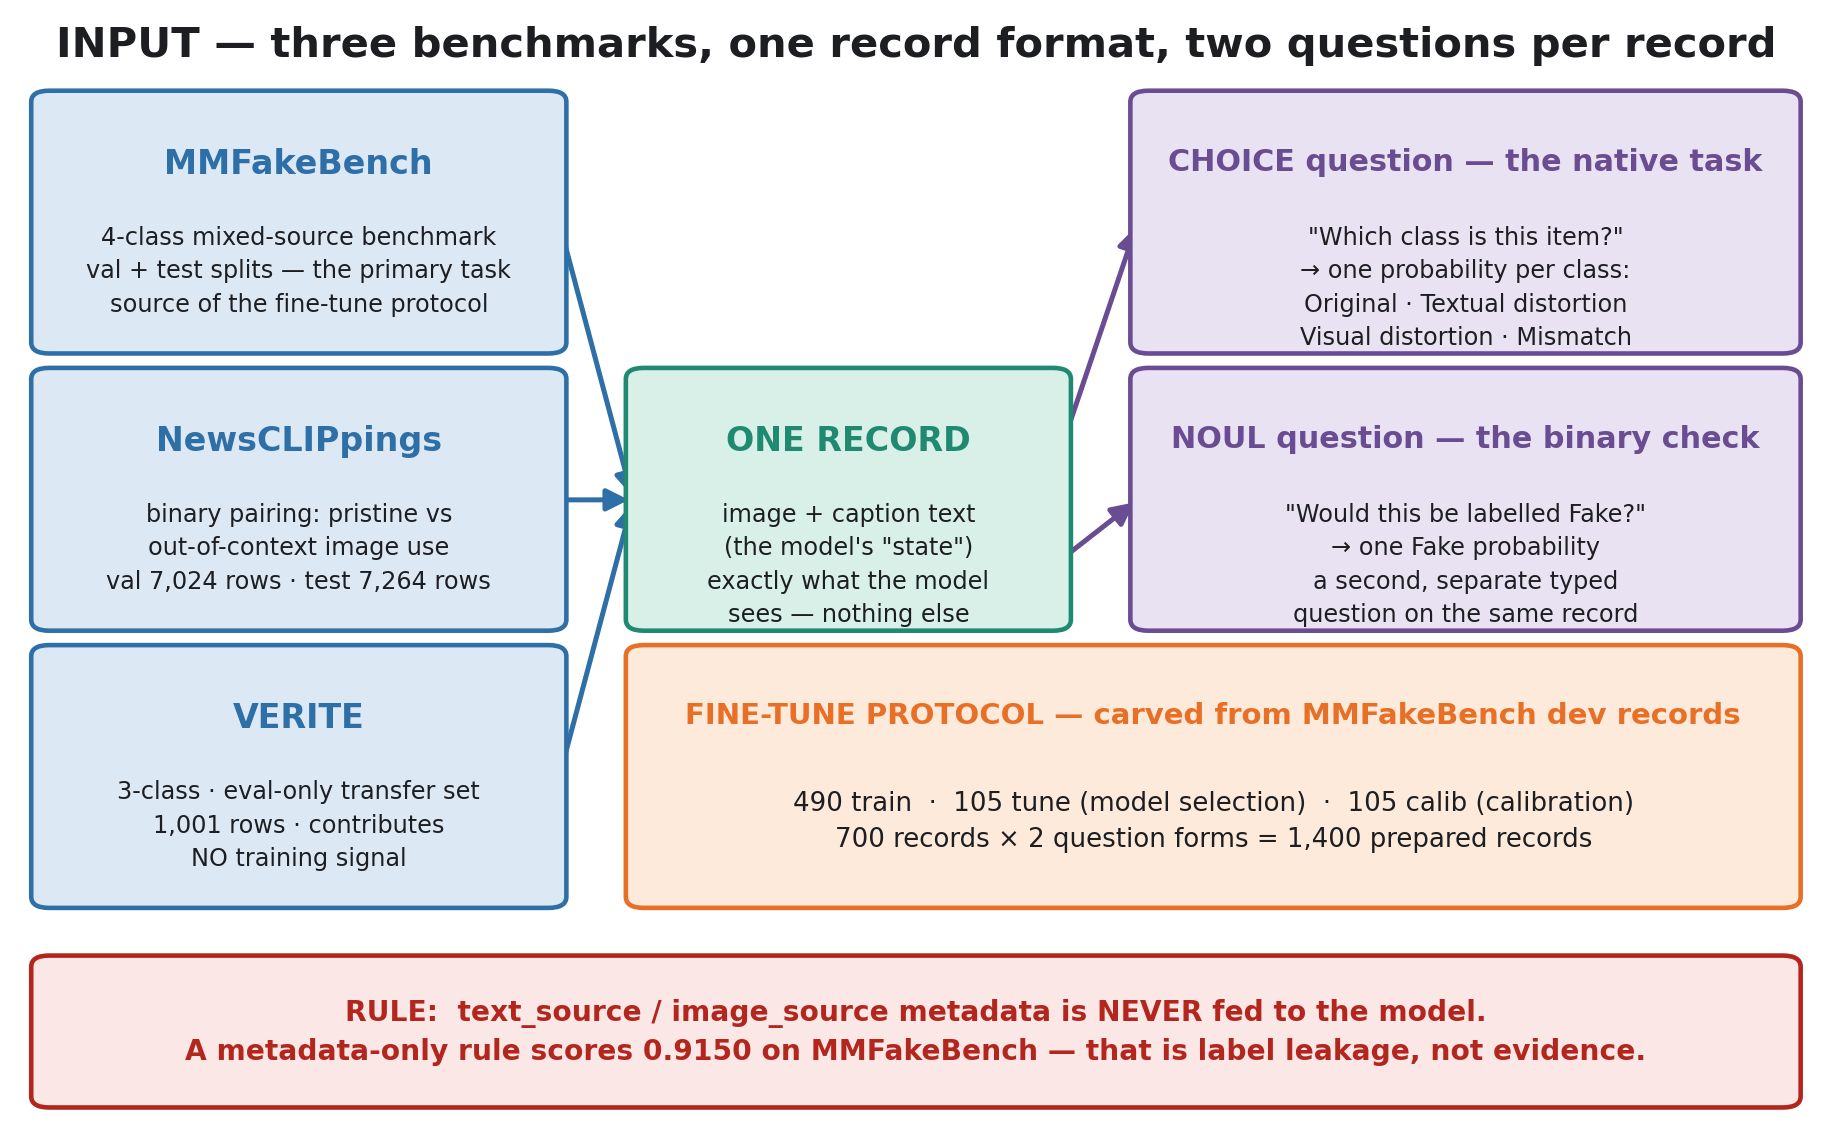

Three standard benchmarks supply the data. Every item reaches the model as **one record — an image plus its caption** — and each record is asked as **two typed questions**: the dataset's native **choice** question (which class is this?) and a binary **noul** question (would this be labelled Fake?). MMFakeBench supplies the core training data, carved into 490 train / 105 tune / 105 calib items; NewsCLIPpings carves its own specialist training set from its TRAIN split only (§7b, design amendment (c)); VERITE is scored, never trained on. Source metadata is never shown to the model — it leaks the label. *Where it lives: the datasets and splits are declared in §0 CONFIG; the gates in §3 verify the records before anything trains.*

### 2 · What happens

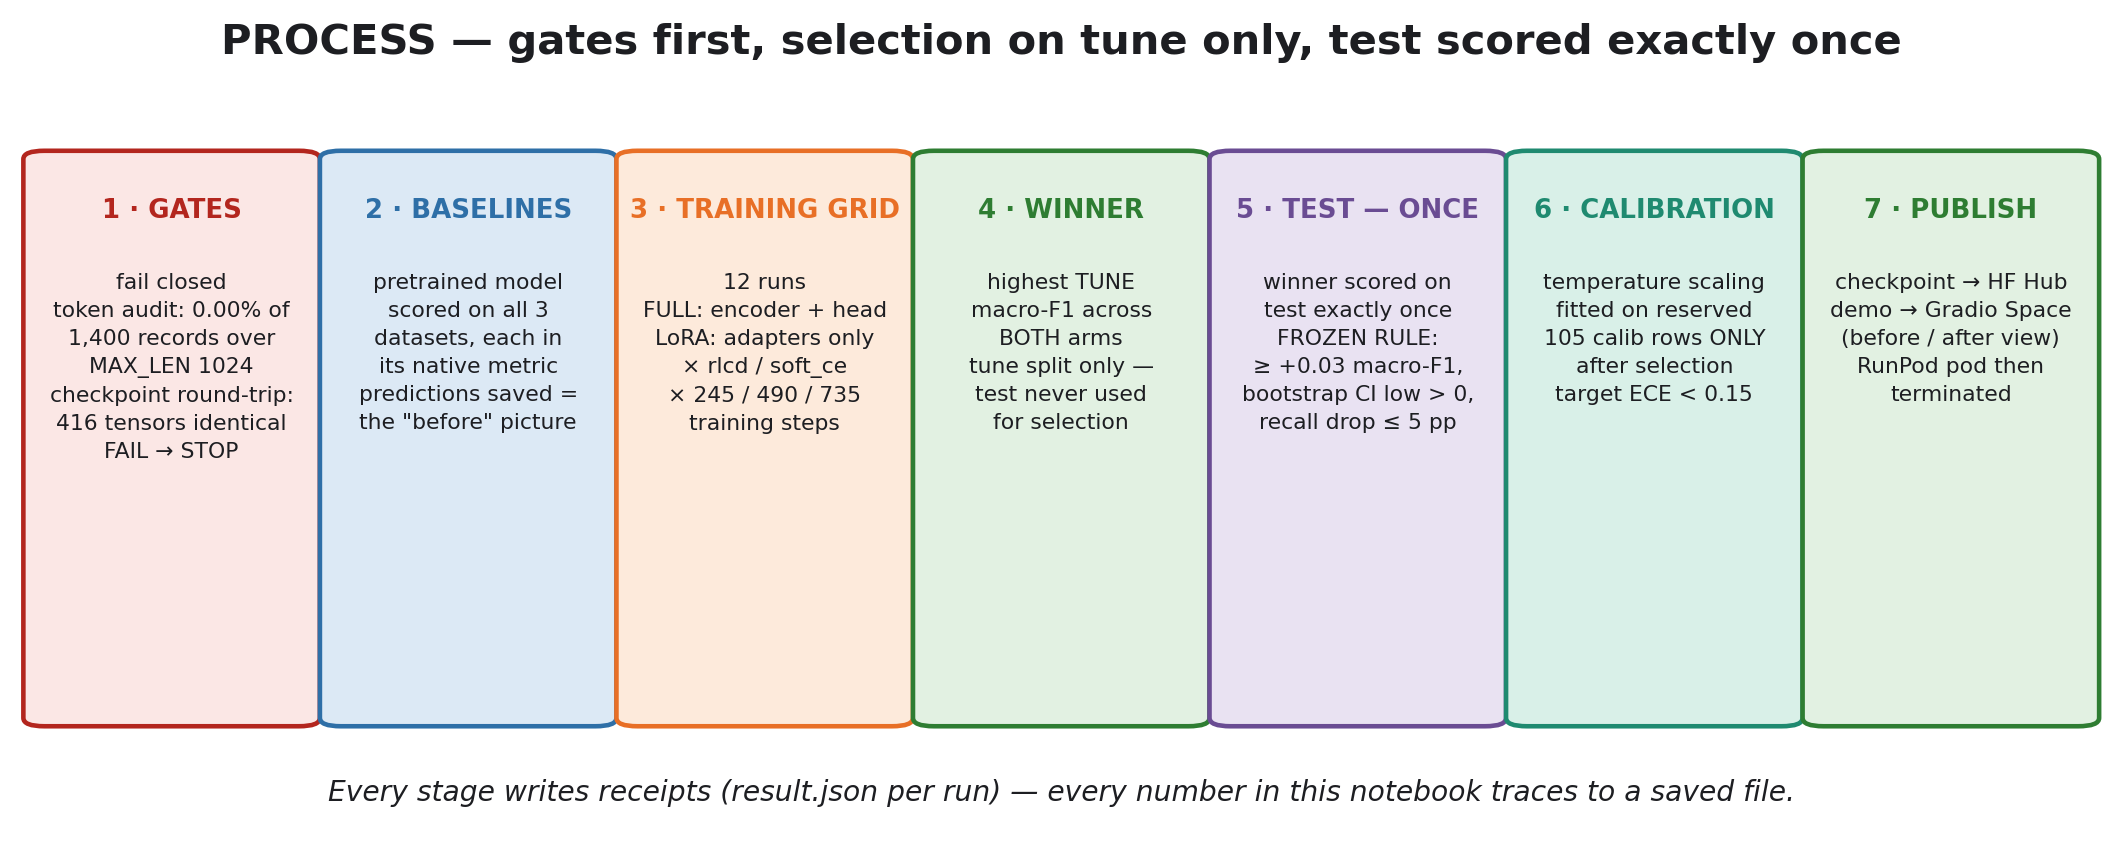

Nothing trains until two fail-closed gates pass. The pretrained model is scored first (the baselines), then a **12-run grid** trains two arms — full fine-tuning and LoRA — and the winner is picked on the **tune split only**. The test split is scored **exactly once**, against a success rule frozen before the run; calibration is fitted afterwards, on its own reserved split; the winning checkpoint is then published to Hugging Face. *Where it lives: gates §3 · baselines §4 · stream §5 · grid §6 · selection §7 · packs §7a · NCP data §7b · NCP training §7c · comparison §8 · verdict §13 · result plots §14 · publish §15.*

### 3 · What comes out

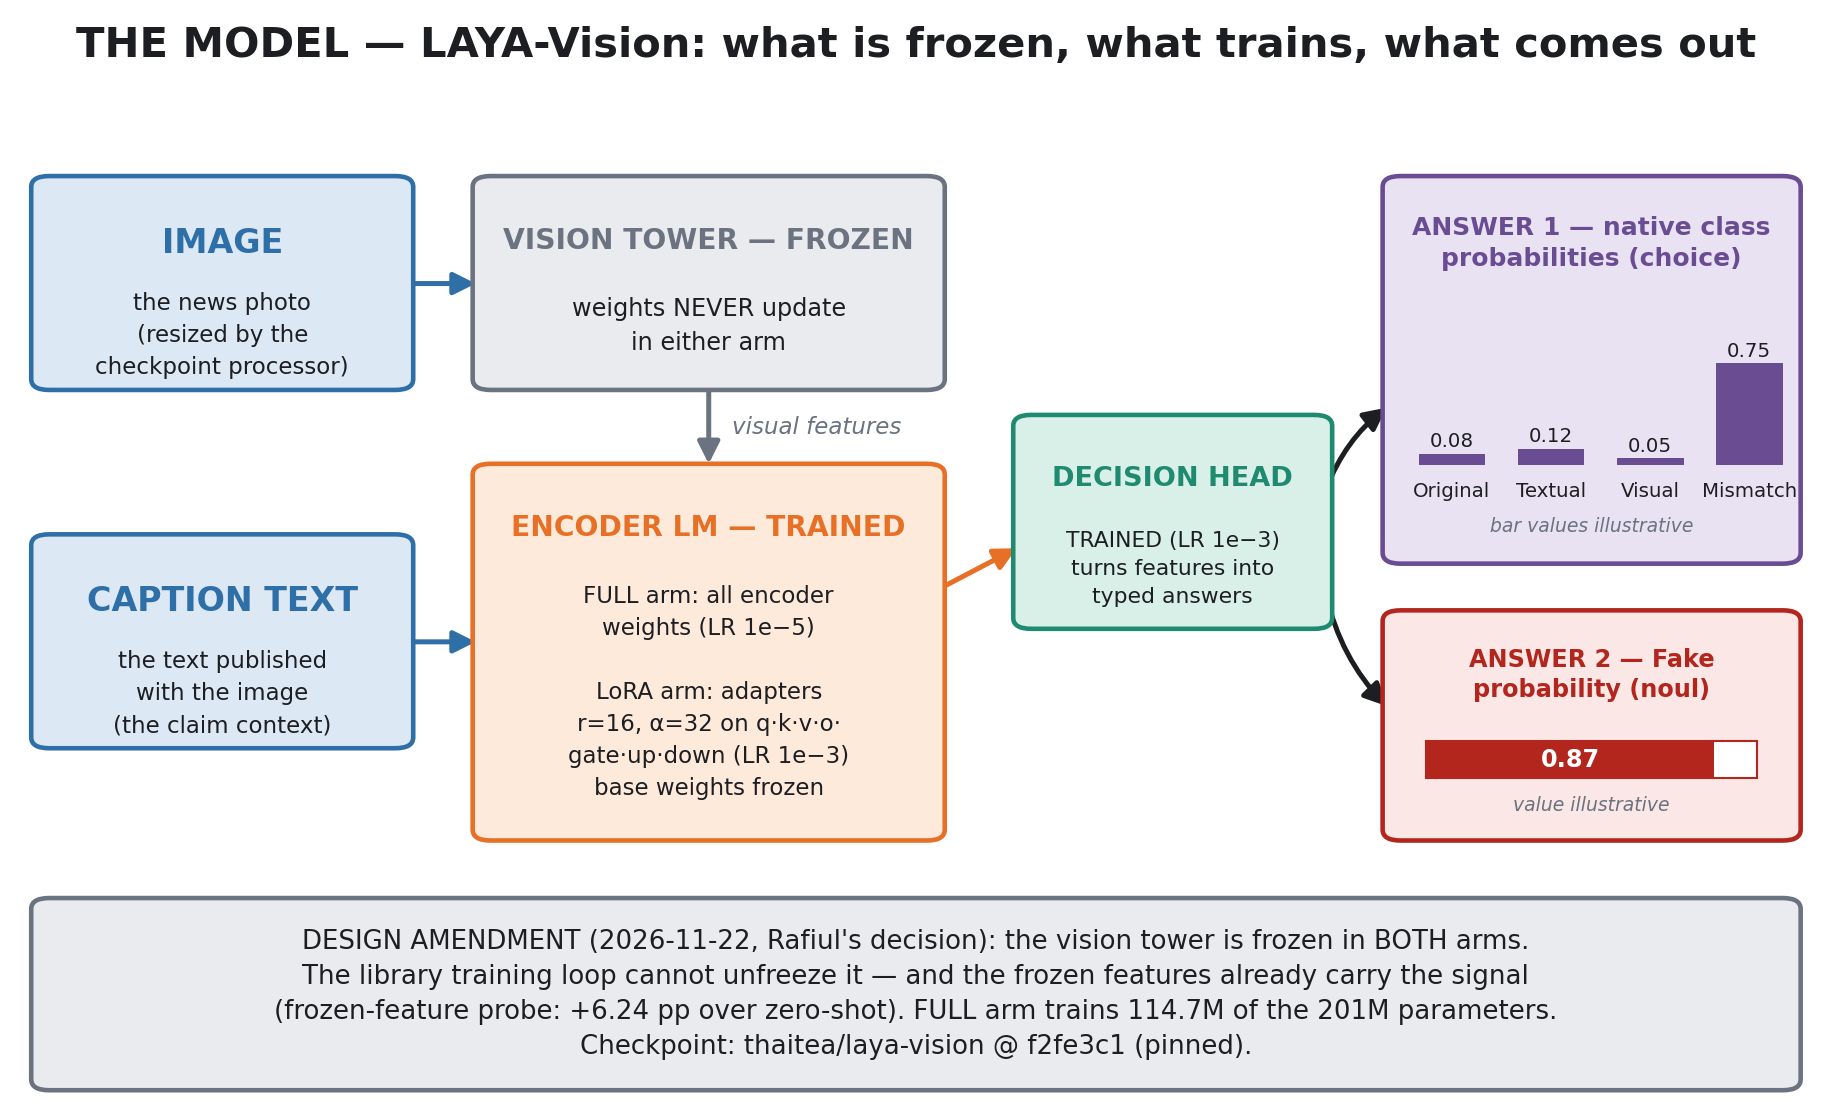

The model is **LAYA-Vision**, a typed-decision vision–language model. Its image tower is **frozen in both arms** — a dated design amendment (2026-11-22), explained in the diagram's banner, not a silent shortcut; training changes only the language encoder and the decision head. For every record the model returns both answers: a probability for each native class, and one Fake probability. The study's headline outputs are the winning checkpoint on the Hub, the live Space demo, and the results table written by §13 · Verdict. *Where it lives: training §6 · publish §15 · paper bundle §16 · complete record §17.*


## 0 · CONFIG — every variable you control lives here

In [7]:
# ===== CONFIG =====
SEED = 20261122

# Model — pinned exactly (do not float)
BASE_MODEL = "thaitea/laya-vision"             # LAYA-Vision paired checkpoint (convaiinnovations/laya is the TEXT model — corrected 2026-11-22, rehearsal-verified)
VISION_REVISION = "f2fe3c12cb6d04c59d8a190250bf3fb40fc828dc"
CKPT_ID = BASE_MODEL            # aliases used by the verification / trainer cells
CKPT_REVISION = VISION_REVISION
MAX_LEN = 1024                  # token budget for the gate audit (= the checkpoint's own max_len)

# Workspace (synced from the Mac mini: /Users/rafiulhaider/Documents/Misinformation)
WORKSPACE = "/workspace/Misinformation"        # pod path after sync
BASELINE_CLI = "data/workflows/run_baseline_study.py"
# Trainer: laya_trainer.py ships with the workspace sync into data/workflows/
# (built 2026-11-22 on laya.vlm_train primitives + the rehearsal-proven peft
# LoRA binding; the trainer cell imports it from there). No trainer module
# existed in the workspace before — the rehearsal proved that.

# Training — FULL fine-tune (encoder LM + head; vision tower frozen in both arms — amended 2026-11-22, option b)
STEP_GRID   = [245, 490, 735]                  # candidate budgets, winner on tune only
LOSSES      = ["rlcd", "soft_ce"]              # Laya default vs soft cross-entropy
LR_ENCODER  = 1e-5                             # low: pretrained features
LR_HEAD     = 1e-3                             # higher: decision head
BATCH_SIZE  = 8
PRECISION   = "bf16"
QUESTION_TYPE = "choice"                       # 4-class choice; 'noul' arm is a separate labelled run

# Training arms (LoRA added 2026-11-22 — Rafiul approved, on the audit's flag)
ARMS        = ["full", "lora"]   # selection spans BOTH arms, tune macro-F1 only
LORA_R      = 16
LORA_ALPHA  = 32
LORA_DROPOUT = 0.05
LORA_LR     = 1e-3               # adapters train hot; base weights stay frozen
LORA_TARGETS = ["q_proj", "v_proj", "k_proj", "o_proj",
                "gate_proj", "up_proj", "down_proj"]  # filtered to modules that exist

# Datasets — native task + metric per dataset (never one metric for all three)
DATASETS = {
    "mmfakebench":   {"task": "4-class",  "metric": "macro_f1", "splits": ["val", "test"]},
    "newsclippings": {"task": "binary pairing (pristine vs out-of-context)", "metric": "accuracy", "splits": ["val", "test"]},
    "verite":        {"task": "3-class",  "metric": "accuracy", "splits": ["val"]},  # eval-only, no train split
}

# Selection / success (primary = MMFakeBench paired)
MIN_GAIN_MACRO_F1 = 0.03        # paired bootstrap 95% CI lower bound must be > 0
MAX_RECALL_DROP_PP = 5.0        # no native class recall may drop more than this

# Publishing
HF_MODEL_REPO = "RafiulHaiderbro/laya-vision-fullft-mmfakebench"
HF_SPACE_REPO = "RafiulHaiderbro/laya-misinfo-demo"

# Run paths (pod workspace layout — every stage below reads/writes exactly these)
BASE_CKPT_DIR = "models/laya-vision-base"     # local snapshot of BASE_MODEL @ VISION_REVISION (the §1 setup cell ensures it; the baseline CLI needs a directory)
MIDTERM_DIR   = "data/processed/midterm"      # eval run dirs: {baseline,trained}_{dataset}_{split}_v1
VISUALNEWS_TAR_URL = "https://www.cs.rice.edu/~vo9/visualnews/origin.tar"  # NewsCLIPpings images: streamed, never saved (§5/§11)
ABLATION_TEST_PREDS_CANDIDATES = [            # Oct 25 ablation: baseline MMFakeBench TEST predictions (9,999 usable, paired macro-F1 0.2037) — pairing partner for the §10 bootstrap
    "data/reports/ablation_test_paired.predictions.jsonl",
    "/root/drivers/ablation_test_paired.predictions.jsonl",
]

# NewsCLIPpings training arm (design amendment (c), 2026-11-22) — lean carve
# from the official TRAIN split only; selection on NCP tune only; val is the
# reported eval; the NCP test split is never touched.
NCP_PROTOCOL_DIR = "data/processed/protocol/newsclippings_finetune_v1"
NCP_CARVE = {"train": 2000, "tune": 250, "calib": 250}   # ITEMS (x2 question forms = records)

# Publishing switch — the §15 publish cell does nothing unless this is True,
# and even then it publishes once (marker runs/.published.json) and says so.
PUBLISH = True

# ===== DATASET PACKS — one registry entry per dataset =====
# The interface is fixed; the questions are data. Each pack carries its own
# native CHOICE question + binary NOUL question (materialized in §1b from the
# frozen study question bank — never retyped here), its label set + display
# mapping, its native metric, its splits, its calibration state (temperatures
# + noul threshold, fitted on THAT dataset's reserved data only), and its
# CHECKPOINT pointer: which weights serve this dataset.
#   mmfakebench   -> "WINNER": the §7 grid winner (its own trained weights)
#   newsclippings -> "NCP_WINNER": its OWN trained arm (amendment (c), §7c)
#   verite        -> base checkpoint (TRANSFER — eval-only)
# To give a transfer dataset its own trained weights later, drop the trained
# checkpoint path into that pack's "checkpoint" — every eval cell resolves
# the pack at call time, so nothing else changes. No dataset's temperatures,
# threshold, or weights are ever read by another dataset's evaluation.
PACKS = {
    "mmfakebench": {
        "labels": ["original", "textual_veracity_distortion", "visual_veracity_distortion", "mismatch"],
        "display": {"original": "Original", "textual_veracity_distortion": "Textual",
                    "visual_veracity_distortion": "Visual", "mismatch": "Mismatch"},
        "metric": "macro_f1", "splits": ["val", "test"],
        "base_checkpoint": BASE_CKPT_DIR,
        "checkpoint": "WINNER",
        "temperatures": None,      # fitted in §12 on the reserved calib split — this dataset only
        "noul_threshold": 0.5,     # the study's evaluation threshold (study.json: evaluation.threshold)
        "questions": None,         # materialized in §1b
    },
    "newsclippings": {
        "labels": ["pristine", "falsified"],
        "display": {"pristine": "Pristine", "falsified": "Falsified (out-of-context)"},
        "binary_negative": ["pristine"],
        "metric": "accuracy", "splits": ["val"],
        "base_checkpoint": BASE_CKPT_DIR,
        "checkpoint": "NCP_WINNER",   # amendment (c): served by its own trained arm (§7b), resolved from runs/ncp_winner.json
        "temperatures": None,          # none fitted (no temperature fit in this run) — the checkpoint's own calibration serves
        "noul_threshold": 0.5,
        "questions": None,
    },
    "verite": {
        "labels": ["true", "miscaptioned", "out-of-context"],
        "display": {"true": "True", "miscaptioned": "Miscaptioned", "out-of-context": "Out-of-context"},
        "metric": "accuracy", "splits": ["val"],
        "base_checkpoint": BASE_CKPT_DIR,
        "checkpoint": BASE_CKPT_DIR,   # TRANSFER serving weights
        "temperatures": None,
        "noul_threshold": 0.5,
        "questions": None,
    },
}


## 1 · Setup — pinned environment, module sync, GPU check (RunPod)

In [9]:
# ===== SETUP — pinned environment, module sync, base checkpoint =====
# Versions are the rehearsal-verified pod environment (2026-11-22). The pod
# image already carries torch; this cell installs the pinned Python packages,
# places the two run modules into data/workflows/, and makes sure the pinned
# base checkpoint exists as a local snapshot for the baseline CLI.
import pathlib, shutil, subprocess, sys

WS = pathlib.Path(WORKSPACE)
WF = WS / "data" / "workflows"
WF.mkdir(parents=True, exist_ok=True)
if str(WF) not in sys.path:
    sys.path.insert(0, str(WF))

PINS = [
    "transformers==5.19.0",
    "peft==0.22.0",
    "laya @ git+https://github.com/r33drichards/laya-vision@9e1e2419d855ad3e1a2af4d4bd1ef6be5418842c",
]
print("Installing pinned packages (idempotent):")
for pin in PINS:
    print("  pip:", pin)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PINS], check=True)

import torch
print("python", sys.version.split()[0])
print("torch", torch.__version__, "| CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "No GPU — this notebook must run on the RunPod pod, not a CPU runtime."
print("GPU:", torch.cuda.get_device_name(0))

import laya, peft, transformers
assert hasattr(laya, "load_vlm") and hasattr(laya, "vlm_train"), \
    "The installed laya has no VLM code — that is the PyPI package. The run needs the DEV install pinned above."
print("laya file:", laya.__file__)
print("transformers", transformers.__version__, "| peft", peft.__version__)
LAYA_SOURCE_ROOT = str(pathlib.Path(laya.__file__).resolve().parent)
print("laya source root (passed to the baseline CLI):", LAYA_SOURCE_ROOT)

# --- module sync: laya_trainer.py + visualnews_stream.py -> data/workflows/ ---
# The modules ship with the workspace sync / staging. If one is missing here,
# this cell FAILS LOUDLY — the run does not proceed on a silent stub.
MODULE_CANDIDATES = [WS, WS / "staging", pathlib.Path("/root/drivers"), pathlib.Path("/root")]
for name in ("laya_trainer.py", "visualnews_stream.py"):
    dest = WF / name
    if dest.exists():
        print(f"module present: {dest}")
        continue
    src = next((c / name for c in MODULE_CANDIDATES if (c / name).exists()), None)
    if src is None:
        raise FileNotFoundError(
            f"{name} not found in the workspace or staging locations "
            f"{[str(c) for c in MODULE_CANDIDATES]}. Sync it into {WF} before "
            f"running this notebook — the run does not proceed without it.")
    shutil.copy2(src, dest)
    print(f"module synced: {src} -> {dest}")
import laya_trainer, visualnews_stream
print("trainer:", laya_trainer.__file__)
print("stream module:", visualnews_stream.__file__)

# --- base checkpoint snapshot (the baseline CLI needs a local directory) ---
BASE_CKPT = WS / BASE_CKPT_DIR
if not BASE_CKPT.is_dir():
    from huggingface_hub import snapshot_download
    print(f"downloading {BASE_MODEL} @ {VISION_REVISION} -> {BASE_CKPT}")
    snapshot_download(BASE_MODEL, revision=VISION_REVISION, local_dir=str(BASE_CKPT))
print("base checkpoint:", BASE_CKPT)
print("SETUP DONE")


Installing pinned packages (idempotent):
  pip: transformers==5.19.0
  pip: peft==0.22.0
  pip: laya @ git+https://github.com/r33drichards/laya-vision@9e1e2419d855ad3e1a2af4d4bd1ef6be5418842c



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip


python 3.11.10
torch 2.14.1+cu130 | CUDA available: True
GPU: NVIDIA GeForce RTX 4090
laya file: /usr/local/lib/python3.11/dist-packages/laya/__init__.py
transformers 5.19.0 | peft 0.22.0
laya source root (passed to the baseline CLI): /usr/local/lib/python3.11/dist-packages/laya
module present: /workspace/Misinformation/data/workflows/laya_trainer.py
module synced: /root/drivers/visualnews_stream.py -> /workspace/Misinformation/data/workflows/visualnews_stream.py
trainer: /workspace/Misinformation/data/workflows/laya_trainer.py
stream module: /workspace/Misinformation/data/workflows/visualnews_stream.py
base checkpoint: /workspace/Misinformation/models/laya-vision-base
SETUP DONE


## 2 · Data — what the sync put on this pod, counted

Asserts every tree the run depends on and prints the inventory. NewsCLIPpings *images* are deliberately absent — they are streamed in §5/§11 and never saved (Rafiul's directive, 2026-11-22); only its annotations live on disk.

In [13]:
# ===== DATA — inventory of the synced workspace (asserts + counts) =====
import csv, json, pathlib

WS = pathlib.Path(WORKSPACE)
PROTO = WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2"

def _count_jsonl(p):
    return sum(1 for line in open(p) if line.strip())

inventory = {}
for split in ("train", "tune", "calib"):
    p = PROTO / f"{split}.jsonl"
    assert p.is_file(), f"missing finetune records: {p} — the workspace sync is incomplete."
    inventory[f"finetune_{split}"] = _count_jsonl(p)
_ft = {k: v for k, v in inventory.items() if k.startswith("finetune")}
print("finetune records:", _ft, "| total:", sum(_ft.values()))

for split in ("val", "test"):
    p = WS / f"data/raw/MMFakeBench/MMFakeBench_{split}.json"
    assert p.is_file(), f"missing MMFakeBench annotations: {p}"
    n = len(json.loads(p.read_text()))
    img_dir = WS / f"data/raw/MMFakeBench/MMFakeBench_{split}"
    n_img = sum(1 for f in img_dir.rglob("*") if f.is_file()) if img_dir.is_dir() else 0
    inventory[f"mmfakebench_{split}"] = {"annotation_rows": n, "image_files": n_img}
    print(f"MMFakeBench {split}: {n} annotation rows, {n_img} image files")
    assert img_dir.is_dir() and n_img > 0, f"MMFakeBench {split} image tree missing/empty: {img_dir}"

verite_csv = WS / "data/raw/VERITE/VERITE.csv"
assert verite_csv.is_file(), f"missing VERITE annotations: {verite_csv}"
with open(verite_csv, newline="") as f:
    n_verite = sum(1 for _ in csv.reader(f)) - 1
n_verite_img = sum(1 for f in (WS / "data/raw/VERITE").rglob("*")
                   if f.is_file() and f.suffix.lower() in {".jpg", ".jpeg", ".png"})
inventory["verite"] = {"rows": n_verite, "image_files": n_verite_img}
print(f"VERITE: {n_verite} rows, {n_verite_img} image files")

ncp_ann = WS / "data/raw/NewsCLIPpings/data/merged_balanced/val.json"
assert ncp_ann.is_file(), f"missing NewsCLIPpings annotations: {ncp_ann}"
_ncp = json.loads(ncp_ann.read_text())
n_ncp = len(_ncp["annotations"]) if isinstance(_ncp, dict) else len(_ncp)
inventory["newsclippings_val"] = {"rows": n_ncp, "images": "stream-only (VisualNews origin.tar, §5/§11)"}
print(f"NewsCLIPpings val: {n_ncp} rows — images are NOT on disk (stream-only)")

_resolved = None
for cand in ABLATION_TEST_PREDS_CANDIDATES:
    p = pathlib.Path(cand) if cand.startswith("/") else WS / cand
    if p.exists():
        _resolved = str(p)
        break
ABLATION_TEST_PREDS = _resolved
inventory["ablation_test_preds"] = ABLATION_TEST_PREDS
print("ablation baseline test predictions (needed in §10):", ABLATION_TEST_PREDS or "NOT FOUND")

(WS / "runs").mkdir(exist_ok=True)
(WS / "runs" / "data_inventory.json").write_text(json.dumps(inventory, indent=1))
print("DATA INVENTORY OK -> runs/data_inventory.json")


finetune records: {'finetune_train': 980, 'finetune_tune': 210, 'finetune_calib': 210} | total: 1400
MMFakeBench val: 1000 annotation rows, 1000 image files
MMFakeBench test: 10000 annotation rows, 934 image files
VERITE: 1001 rows, 663 image files
NewsCLIPpings val: 7024 rows — images are NOT on disk (stream-only)
ablation baseline test predictions (needed in §10): /workspace/Misinformation/data/reports/ablation_test_paired.predictions.jsonl
DATA INVENTORY OK -> runs/data_inventory.json


## 3 · Pre-training verifications (fail closed)
- All-row tokenization audit: count rows whose state+question exceeds the token budget — Laya SKIPS over-long items instead of truncating, so any skip must be a number we know, not a surprise.
- Checkpoint save/load round-trip on the base checkpoint before any training.

*Rationale for both gates is recorded in the Research design section above (tokenization skip behaviour; checkpoint round-trip integrity).*


In [15]:
# ===== VERIFICATIONS — fail closed =====
# Gate 1: tokenization audit on the prepared records.
# LAYA skips over-long items rather than truncating them, so we measure the
# length distribution BEFORE training and report how many records would be
# skipped at MAX_LEN. A silent skip is a silent data change.
# Rewritten 2026-11-22 to the rehearsal-verified form: the audit runs on the
# LAYA-Vision checkpoint's OWN processor (thaitea/laya-vision @ VISION_REVISION)
# over each record's state_text. (The earlier draft tokenized a "text" field
# the records do not carry, via an AutoTokenizer on the text-model repo, with
# undefined names — the rehearsal ran it and it failed. This cell is the
# rehearsal's Gate B, which PASSED: 0.00% of 1,400 records over MAX_LEN.)
import json, pathlib, statistics
import laya

agent = laya.load_vlm(BASE_MODEL, revision=VISION_REVISION)
tok = agent.processor.tokenizer

DATA_DIR = pathlib.Path(WORKSPACE) / "data" / "processed" / "protocol" / "mmfakebench_finetune_dev_choice_v2"
lengths, skipped = [], 0
for split in ("train", "tune", "calib"):  # files: train/tune/calib.jsonl
    for line in open(DATA_DIR / f"{split}.jsonl"):
        rec = json.loads(line)
        n = len(tok(rec["state_text"], add_special_tokens=False)["input_ids"])
        lengths.append(n)
        skipped += int(n > MAX_LEN)
lengths.sort()
print(f"records={len(lengths)} mean={statistics.mean(lengths):.0f} "
      f"p50={lengths[len(lengths)//2]} p95={lengths[int(len(lengths)*0.95)]} max={lengths[-1]}")
print(f"would be SKIPPED at MAX_LEN={MAX_LEN}: {skipped} ({100*skipped/len(lengths):.2f}%)")
assert skipped / len(lengths) < 0.02, "Skip rate too high - raise MAX_LEN or re-prepare data before training."

# Gate 2: checkpoint save/load round-trip (a checkpoint that cannot reload is not a result).
# Laya-native: VLMAgent.save -> laya.load_vlm, every tensor compared
# (rehearsal Gate C: 416 tensors, bit-identical).
import tempfile, torch
with tempfile.TemporaryDirectory() as td:
    agent.save(td)
    _a2 = laya.load_vlm(td)
    _sd1, _sd2 = agent.model.state_dict(), _a2.model.state_dict()
    same = list(_sd1) == list(_sd2) and all(torch.equal(_sd1[k], _sd2[k]) for k in _sd1)
    n_tensors = len(_sd1)
del _a2
print(f"save/load round-trip identical: {same} ({n_tensors} tensors)")
assert same
print("VERIFICATIONS PASSED")

# Receipt for the record (§17 bundle reads this file).
pathlib.Path(WORKSPACE, "runs").mkdir(exist_ok=True)
pathlib.Path(WORKSPACE, "runs", "gates.json").write_text(json.dumps({
    "gate1_token_audit": {"records": len(lengths), "mean": statistics.mean(lengths),
                          "p50": lengths[len(lengths) // 2], "p95": lengths[int(len(lengths) * 0.95)],
                          "max": lengths[-1], "skipped": skipped,
                          "skipped_pct": 100 * skipped / len(lengths), "max_len": MAX_LEN},
    "gate2_roundtrip": {"tensors": n_tensors, "bit_identical": bool(same)},
    "checkpoint": f"{BASE_MODEL} @ {VISION_REVISION}"}, indent=1))
print("gate receipts -> runs/gates.json")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


records=1400 mean=18 p50=17 p95=32 max=43
would be SKIPPED at MAX_LEN=1024: 0 (0.00%)
save/load round-trip identical: True (416 tensors)
VERIFICATIONS PASSED
gate receipts -> runs/gates.json


## 4 · Baseline eval — pretrained, MMFakeBench val + VERITE (paired route)

Uses the workspace baseline CLI. NOTE the flag form: `--set` takes separate args, and override values are JSON-encoded strings (the Oct 25 stage-5 bug was passing '--set vision.batch_size=1' as one string). The CLI refuses an existing output directory, so the helper below reuses complete artifacts, resumes partial ones, and runs fresh otherwise — and says which, out loud.

*NewsCLIPpings has no baseline here: its images are not on disk. Its baseline is the §5 stream PASS 1, scored by the same study code.*

In [17]:
# ===== EVAL HELPER + BASELINES — the workspace baseline CLI, paired branch =====
import pathlib, subprocess, sys

WS = pathlib.Path(WORKSPACE)

def run_eval_cli(dataset, split, checkpoint, out_rel):
    """Run (or reuse/resume) one paired baseline-CLI eval; returns the run dir.
    Complete artifacts on disk -> reused (announced). Partial -> --resume.
    Absent -> fresh run. A failed CLI raises here, never silently."""
    out = WS / out_rel
    if (out / "paired.predictions.jsonl").exists() and (out / "paired.metrics.json").exists():
        print(f"[reuse] {out_rel} — paired predictions + metrics already on disk")
        return out
    cmd = [sys.executable, str(WS / BASELINE_CLI),
           "--set", "sampling.per_class=null", "--set", "sampling.limit=null",
           "--set", f'vision.python="{sys.executable}"',
           "--set", f'vision.checkpoint="{checkpoint}"',
           "--set", f'vision.source_root="{LAYA_SOURCE_ROOT}"',
           "--set", 'vision.device="cuda"', "--set", 'vision.dtype="bf16"',
           "--set", f'datasets.verite.annotations="{WS}/data/raw/VERITE/VERITE.csv"',
           "--set", f'datasets.verite.images="{WS}/data/raw/VERITE"',
           "run", "--dataset", dataset, "--split", split,
           "--partition", "all", "--purpose", "evaluation",
           "--branch", "paired", "--output", str(out)]
    if out.exists():
        cmd.append("--resume")
        print(f"[resume] {out_rel} — partial artifacts on disk, resuming")
    print(" ".join(cmd))
    subprocess.run(cmd, check=True, cwd=WORKSPACE)
    assert (out / "paired.predictions.jsonl").exists(), f"CLI finished but no predictions at {out}"
    return out

def eval_metrics(out_rel):
    import json as _json
    m = _json.loads((WS / out_rel / "paired.metrics.json").read_text())
    return {"accuracy": m["native"]["accuracy"], "macro_f1": m["native"]["macro_f1"],
            "usable": m["usable"], "attempted": m["attempted"]}

for ds in ("mmfakebench", "verite"):
    _pack = PACKS[ds]
    _ck = str(WS / _pack["base_checkpoint"])
    print(f"now serving: {ds} / weights: {_ck} (baseline pass — the pack's base_checkpoint)")
    run_eval_cli(ds, "val", _ck, f"{MIDTERM_DIR}/baseline_{ds}_val_v1")
    print(f"{ds} val baseline:", eval_metrics(f"{MIDTERM_DIR}/baseline_{ds}_val_v1"))
print("Baselines on disk: MMFakeBench val + VERITE val (paired). NewsCLIPpings baseline = §5 stream PASS 1.")


now serving: mmfakebench / weights: /workspace/Misinformation/models/laya-vision-base (baseline pass — the pack's base_checkpoint)
[reuse] data/processed/midterm/baseline_mmfakebench_val_v1 — paired predictions + metrics already on disk
mmfakebench val baseline: {'accuracy': 0.293, 'macro_f1': 0.20791501063690315, 'usable': 1000, 'attempted': 1000}
now serving: verite / weights: /workspace/Misinformation/models/laya-vision-base (baseline pass — the pack's base_checkpoint)
[reuse] data/processed/midterm/baseline_verite_val_v1 — paired predictions + metrics already on disk
verite val baseline: {'accuracy': 0.34665334665334663, 'macro_f1': 0.2818864153259848, 'usable': 1001, 'attempted': 1001}
Baselines on disk: MMFakeBench val + VERITE val (paired). NewsCLIPpings baseline = §5 stream PASS 1.


## 5 · NewsCLIPpings — the VisualNews stream leg (images are never saved)

VisualNews ships as one 91 GB `origin.tar`; the pod's disk cannot hold it, and Rafiul's directive (2026-11-22) is that the images are **streamed, not saved**. So this leg consumes the tar in ONE streaming pass over HTTP: each referenced member is verified **in memory** by `visualnews_stream.verify_image_bytes` (full PIL decode; either side < 8 px = degenerate), handed to the model as a PIL image, and discarded. Nothing is written to disk except predictions and accounting.

Inference mirrors the baseline CLI's paired branch exactly — same validated items (`baseline_study.datasets`), same questions (`baseline_study.config.questions`), the same `agent.predict` call the vision worker makes, the same `decode_answers` / `validate_prediction` / `score_records`. (Transport equivalence — stock worker on a file path vs in-process PIL — was gated headless before this notebook run: max probability delta 0.0 on 3 val items.)

**Verifier rules (directive #2):** skips are INTEGRITY-ONLY (never content, never model uncertainty); a bad image is written as a `blocked` row and into the skip ledger, and the pass continues; accuracy is computed over the SCORED rows and labelled as such; accounting is reported per source (bbc / guardian / usa_today / washington_post).

This function runs TWICE: **PASS 1** below (base checkpoint = the NewsCLIPpings baseline) and **PASS 2** in §11 (the winner). It is resume-safe: rows already scored in an existing predictions file are verified but not re-predicted.
The pass is driven by the **newsclippings pack** (§1b): its labels, its questions, its checkpoint — loaded for this pass and unloaded after, so no other dataset's weights, temperatures, or threshold can leak into this evaluation.

In [19]:
# ===== STREAM FUNCTION — one VisualNews pass for a checkpoint =====
# Adapted from the run's proven stream driver (drivers/stream_ncp.py); the
# stream/verify/accounting core is visualnews_stream.py (§1 synced it into
# data/workflows). Returns the paired metrics dict; also writes, per pass:
# paired.predictions.jsonl, paired.metrics.json, summary.json, manifest.json,
# stream_skip_ledger.jsonl, stream_accounting.json — and PRINTS the full
# accounting (image level + row level, per source) at the end of the pass.
import json, os, sys, time
from collections import Counter
from pathlib import Path

WS = Path(WORKSPACE)
os.chdir(WS)  # the study code resolves dataset paths relative to the workspace

from baseline_study.config import load_config, questions, sha_file, signature
from baseline_study.datasets import LABELS, load_records
from baseline_study.engine import decode_answers, validate_prediction
from baseline_study.metrics import score_records
from visualnews_stream import stream_verified

# labels + binary negative come from the newsclippings PACK at call time
SOURCES_NCP = ("bbc", "guardian", "usa_today", "washington_post")

def run_ncp_stream(pack, checkpoint, out_rel):
    output = WS / out_rel
    output.mkdir(parents=True, exist_ok=True)
    print(f"now serving: newsclippings / weights: {checkpoint}")
    LABELS_NCP = tuple(pack["labels"])
    NEGATIVE_NCP = pack.get("binary_negative", ["pristine"])
    overrides = [
        "sampling.per_class=null", "sampling.limit=null",
        f'vision.python="{sys.executable}"',
        f"vision.checkpoint={json.dumps(checkpoint)}",
        f'vision.source_root="{LAYA_SOURCE_ROOT}"',
        'vision.device="cuda"', 'vision.dtype="bf16"',
    ]
    config, bank = load_config(WS / "data/workflows/baseline_study/study.json", overrides)
    rows = load_records("newsclippings", config["datasets"]["newsclippings"], "val")
    images_root = Path(config["datasets"]["newsclippings"]["images"])
    q = pack["questions"]  # the pack's frozen native choice + fake noul questions (§1b)
    vcfg = config["vision"]

    def member_key(row):
        rel = Path(row["image_path"]).relative_to(images_root)  # visual_news/origin/...
        parts = rel.parts
        if parts[0] == "visual_news":
            rel = Path(*parts[1:])  # origin/<source>/images/...
        return str(rel)

    groups = {}
    for row in rows:
        groups.setdefault(member_key(row), []).append(row)
    print(f"rows={len(rows)} unique_images={len(groups)}", flush=True)

    pred_path = output / "paired.predictions.jsonl"
    saved = {}
    if pred_path.exists():
        for line in pred_path.read_text().splitlines():
            if line.strip():
                item = json.loads(line)
                saved[item["id"]] = item
    done_ids = {rid for rid, it in saved.items() if it.get("status") == "ok"}
    print(f"resume: {len(done_ids)} rows already scored", flush=True)

    run_id = signature({"method": "visualnews-stream-v2", "config": config,
                        "questions_sha256": sha_file(config["questions_file"])})

    import laya
    import torch
    agent = laya.load_vlm(checkpoint, device=vcfg["device"], dtype=vcfg["dtype"],
                          max_len=vcfg["max_len"], head_max_len=vcfg["head_max_len"])
    worker_identity = {"checkpoint": checkpoint, "device": str(agent.device),
                       "temperature": [float(x) for x in agent.temperature],
                       "transport": "in-process PIL (visualnews_stream verified RGB)"}
    (output / "vision.runtime.json").write_text(json.dumps(worker_identity, indent=2) + "\n")

    sink = open(pred_path, "a")

    def base_item(row):
        item = {k: row[k] for k in ("id", "dataset", "split", "partition", "gold", "group_id")}
        item.update(run_id=run_id, branch="paired", status="blocked",
                    predicted_label=None, probabilities=None, fake_probability=None)
        return item

    def emit(item):
        sink.write(json.dumps(item, allow_nan=False) + "\n")
        sink.flush()
        saved[item["id"]] = item

    predict_errors = Counter()

    def on_image(path, image):
        """path = referenced key (origin/<source>/...); image = verified PIL RGB."""
        made = []
        for row in groups[path]:
            if row["id"] in done_ids:
                continue
            item = base_item(row)
            start = time.monotonic()
            try:
                if not (row["text"] or "").strip():
                    raise LookupError("Required text is missing")
                state = {"context": row["text"] or "", "image": image}
                with torch.inference_mode():
                    result = agent.predict(
                        state, q, n_permutations=vcfg["n_permutations"],
                        batch_size=vcfg["batch_size"], prefix_cache=vcfg["prefix_cache"],
                        temperature=vcfg["temperature"], strict=vcfg["strict"])
                item.update(decode_answers(result, LABELS_NCP))
                item["status"] = "ok"
                validate_prediction(item, LABELS_NCP)
                item["abstained"] = False
            except LookupError as exc:
                item.update(status="blocked", reason=str(exc))
            except Exception as exc:
                predict_errors[type(exc).__name__] += 1
                item.update(status="error", reason=repr(exc))
            item["seconds"] = round(time.monotonic() - start, 4)
            emit(item)
            made.append(item)
        return made

    aborted, ledger = None, None
    try:
        _results, ledger = stream_verified(VISUALNEWS_TAR_URL, groups, on_image)
    except Exception as exc:  # stream-level failure: scored rows are kept; a re-run resumes
        aborted = repr(exc)
        print(f"STREAM ABORTED (restartable): {aborted}", flush=True)
    sink.close()
    del agent
    torch.cuda.empty_cache()
    print(f"unloaded: newsclippings weights ({checkpoint}) — no weights stay resident between packs")

    # Reconcile rows that never got an item: verifier skips + missing members.
    # ONLY on a completed pass — on an aborted pass, unseen members are merely
    # unprocessed (the resume pass will reach them), not missing.
    skip_reason_by_member, missing_members = {}, set()
    if aborted is None and ledger is not None:
        skip_reason_by_member = {p: r for p, r in ledger.skips}
        missing_members = set(groups)
        for m, grows in groups.items():
            if m in skip_reason_by_member:
                missing_members.discard(m)
            elif any(r["id"] in saved for r in grows):
                missing_members.discard(m)
        with open(pred_path, "a") as sink2:
            for m in missing_members | set(skip_reason_by_member):
                reason = (f"stream_verifier_skip:{skip_reason_by_member[m]}"
                          if m in skip_reason_by_member else "member_not_in_stream")
                for row in groups[m]:
                    if row["id"] in saved:
                        continue
                    item = base_item(row)
                    item["reason"] = reason
                    sink2.write(json.dumps(item, allow_nan=False) + "\n")
                    saved[item["id"]] = item

    def source_of_member(m):
        for seg in m.split("/"):
            if seg in SOURCES_NCP:
                return seg
        return "other"

    row_acct = {}
    for m, grows in groups.items():
        src = source_of_member(m)
        a = row_acct.setdefault(src, {"referenced_rows": 0, "scored_rows": 0,
                                      "skipped_rows": 0, "error_rows": 0,
                                      "skip_reasons": Counter()})
        for row in grows:
            a["referenced_rows"] += 1
            item = saved.get(row["id"])
            if item is None:
                continue
            if item["status"] == "ok":
                a["scored_rows"] += 1
            elif item["status"] == "error":
                a["error_rows"] += 1
            else:
                a["skipped_rows"] += 1
                a["skip_reasons"][str(item.get("reason", "blocked")).split(":")[0]] += 1
    for a in row_acct.values():
        a["skip_reasons"] = dict(a["skip_reasons"])

    items = list(saved.values())
    metrics = score_records(items, LABELS_NCP, NEGATIVE_NCP, config["evaluation"]["threshold"])
    metrics["purpose"] = "evaluation"
    for report in metrics["by_partition"].values():
        report["selection_eligible"] = False
    (output / "paired.metrics.json").write_text(json.dumps(metrics, indent=2, allow_nan=False) + "\n")
    summary = {"run_id": run_id, "purpose": "evaluation",
               "branches": {"paired": {k: metrics[k] for k in ("attempted", "usable", "error", "blocked", "abstention")}},
               "training_run": False}
    (output / "summary.json").write_text(json.dumps(summary, indent=2) + "\n")
    with open(output / "stream_skip_ledger.jsonl", "w") as lf:
        if ledger is not None:
            for path, reason in ledger.skips:
                lf.write(json.dumps({"member": path, "source": source_of_member(path),
                                     "reason": reason,
                                     "row_ids": [r["id"] for r in groups[path]]}) + "\n")
        for m in sorted(missing_members):
            if m not in skip_reason_by_member:
                lf.write(json.dumps({"member": m, "source": source_of_member(m),
                                     "reason": "missing_from_stream",
                                     "row_ids": [r["id"] for r in groups[m]]}) + "\n")
    (output / "stream_accounting.json").write_text(json.dumps({
        "tar_url": VISUALNEWS_TAR_URL, "checkpoint": checkpoint, "aborted": aborted,
        "image_level_ledger": ledger.summary() if ledger is not None else None,
        "row_level_per_source": row_acct,
        "predict_errors": dict(predict_errors),
        "note": "NewsCLIPpings accuracy is computed over the scored (usable) rows only.",
    }, indent=2) + "\n")
    (output / "manifest.json").write_text(json.dumps({
        "run_id": run_id, "method": "visualnews-stream-v2",
        "directive": "VisualNews images streamed, never saved (Rafiul, 2026-11-22); "
                     "verifier = visualnews_stream.verify_image_bytes (full PIL decode, "
                     "min dimension 8px, integrity-only skips with ledger) per directive #2.",
        "config": config, "questions_sha256": sha_file(config["questions_file"]),
        "worker_identity": worker_identity,
    }, indent=2) + "\n")

    # ---- FULL accounting, printed (this output is part of the record) ----
    print(f"\n=== STREAM ACCOUNTING — {out_rel} ===")
    if ledger is not None:
        ls = ledger.summary()
        print(f"images: referenced={ls['referenced']} seen={ls['seen_in_stream']} "
              f"verified={ls['verified']} skipped={ls['skipped']} missing={ls['missing_from_stream']}")
        print(f"skip reasons: {ls['skip_reasons']}")
        print("per source (image level):")
        for s, c in ls["per_source"].items():
            print(f"  {s:16s} {c}")
    print("per source (row level):")
    for s, a in sorted(row_acct.items()):
        print(f"  {s:16s} referenced={a['referenced_rows']} scored={a['scored_rows']} "
              f"skipped={a['skipped_rows']} errors={a['error_rows']} reasons={a['skip_reasons']}")
    print(f"accuracy over SCORED rows: {metrics['native']['accuracy']:.4f} "
          f"(usable {metrics['usable']} / attempted {metrics['attempted']}) | aborted: {aborted}")
    if aborted is not None:
        raise RuntimeError(f"stream pass aborted ({aborted}) — re-run this cell; scored rows resume.")
    return metrics


### Stream PASS 1 — base checkpoint (the NewsCLIPpings baseline)

In [21]:
# ===== STREAM PASS 1 — NewsCLIPpings val, BASE checkpoint =====
ncp_base_metrics = run_ncp_stream(PACKS["newsclippings"], str(WS / BASE_CKPT_DIR), f"{MIDTERM_DIR}/baseline_newsclippings_val_v1")
print("NewsCLIPpings baseline accuracy (over scored rows):", ncp_base_metrics["native"]["accuracy"])


now serving: newsclippings / weights: /workspace/Misinformation/models/laya-vision-base
rows=7024 unique_images=5943
resume: 0 rows already scored


[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.
/usr/local/lib/python3.11/dist-packages/transformers/utils/generic.py:943: FutureWarning: `image_hidden_states` is deprecated and will be removed in version v5.20 for `Idefics3Model.forward`. Use `mm_encoder_outputs` instead.
  output = func(self, *args, **kwargs)
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be remo

## 6 · Training — the 12-run grid (FULL + LoRA × rlcd + soft_ce × 245/490/735)

Grid = ARMS × STEP_GRID × LOSSES, run in ascending step order so the trainer proves itself end-to-end on the cheapest config before real spend. FULL arm: differential LR (encoder LM at LR_ENCODER, head at LR_HEAD; vision tower frozen — amended 2026-11-22, option b). LoRA arm: base frozen, adapters (LORA_R/LORA_ALPHA) at LORA_LR, head at LR_HEAD. Every run writes a receipt (`runs/<arm>_<loss>_<steps>/result.json`: full config, loss curve, tune macro-F1, per-class recall) and is resume-safe — a config with an existing receipt is read back, not re-trained.

*Why two arms, and why these hyperparameters: see the Research design section (decisions table, [4] [5]) and the §8 method panels.*

In [25]:
# ===== TRAINING GRID — 12 configs, ascending steps, winner on TUNE only =====
# In-process via laya_trainer (§1 synced it into data/workflows). Training
# uses every record in the train file (both question forms, as prepared);
# the selection metric — tune macro-F1 — is computed on the 4-class form only.
import json, pathlib, time
import laya_trainer

WS = pathlib.Path(WORKSPACE)
TRAIN_FILE = str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/train.jsonl")
TUNE_FILE  = str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/tune.jsonl")
CALIB_FILE = str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/calib.jsonl")

grid = {}
order = [(arm, loss, steps) for steps in STEP_GRID for loss in LOSSES for arm in ARMS]
for arm, loss, steps in order:
    name = f"{arm}_{loss}_{steps}"
    receipt_path = WS / "runs" / name / "result.json"
    if receipt_path.exists():
        f1 = json.loads(receipt_path.read_text())["tune_macro_f1"]
        grid[(arm, loss, steps)] = f1
        print(f"[receipt] {name}: tune macro-F1 = {f1:.4f} (already trained)")
        continue
    print(f"[train] {name} ...", flush=True)
    t0 = time.time()
    if arm == "full":
        out = laya_trainer.train_full_finetune(
            ckpt_id=CKPT_ID, revision=CKPT_REVISION, loss=loss, max_steps=steps,
            lr_encoder=LR_ENCODER, lr_head=LR_HEAD, seed=SEED,
            train_file=TRAIN_FILE, tune_file=TUNE_FILE,
            out_dir=str(WS / "runs" / name))
    else:
        out = laya_trainer.train_lora_finetune(
            ckpt_id=CKPT_ID, revision=CKPT_REVISION, loss=loss, max_steps=steps,
            lora_r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
            lora_targets=LORA_TARGETS, lr_lora=LORA_LR, lr_head=LR_HEAD,
            seed=SEED, train_file=TRAIN_FILE, tune_file=TUNE_FILE,
            out_dir=str(WS / "runs" / name))
    grid[(arm, loss, steps)] = out["tune_macro_f1"]
    print(f"[done] {name}: tune macro-F1 = {out['tune_macro_f1']:.4f} "
          f"({time.time() - t0:.0f}s, trainable params = {out['trainable_params']:,})", flush=True)

print("\n=== GRID — tune macro-F1 (the selection metric) ===")
for (arm, loss, steps), f1 in sorted(grid.items()):
    print(f"  {arm:5s} {loss:8s} @ {steps:3d} steps : {f1:.4f}")
assert len(grid) == len(ARMS) * len(LOSSES) * len(STEP_GRID), "grid incomplete — selection must not run"


[train] full_rlcd_245 ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


sampling mix (alpha=0, before max_passes): mmfakebench 1.000
training 114728323 params (freeze=full) on cuda:0, batch 8, amp=True


/usr/local/lib/python3.11/dist-packages/transformers/utils/generic.py:943: FutureWarning: `image_hidden_states` is deprecated and will be removed in version v5.20 for `Idefics3Model.forward`. Use `mm_encoder_outputs` instead.
  output = func(self, *args, **kwargs)
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`


... (6,518 outputs left out)

[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in 

soft_ce step 730 | loss 0.0160 | lr 1.00e-04


[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in 

[done] lora_soft_ce_735: tune macro-F1 = 0.7187 (516s, trainable params = 12,603,715)

=== GRID — tune macro-F1 (the selection metric) ===
  full  rlcd     @ 245 steps : 0.5667
  full  rlcd     @ 490 steps : 0.5880
  full  rlcd     @ 735 steps : 0.6061
  full  soft_ce  @ 245 steps : 0.5954
  full  soft_ce  @ 490 steps : 0.6598
  full  soft_ce  @ 735 steps : 0.7389
  lora  rlcd     @ 245 steps : 0.4597
  lora  rlcd     @ 490 steps : 0.4505
  lora  rlcd     @ 735 steps : 0.1946
  lora  soft_ce  @ 245 steps : 0.6282
  lora  soft_ce  @ 490 steps : 0.5726
  lora  soft_ce  @ 735 steps : 0.7187


## 7 · Selection — the winner, on tune only

One number decides: tune macro-F1, best across BOTH arms. The frozen success rule (≥ +0.03 macro-F1 over baseline AND bootstrap CI lower bound > 0 AND no class recall drop > 5 pp) is **not** judged here — selection and verdict stay separate; §13 judges.

In [27]:
# ===== SELECTION — winner = best tune macro-F1 across BOTH arms =====
import json, pathlib

WS = pathlib.Path(WORKSPACE)
receipts = {}
for rj in sorted((WS / "runs").glob("*/result.json")):
    if rj.parent.name.startswith("ncp_"):
        continue  # the NCP arm's receipts are a separate registry (§7b)
    r = json.loads(rj.read_text())
    receipts[(r["arm"], r["loss"], r["steps"])] = r
assert len(receipts) == 12, f"selection needs all 12 receipts, found {len(receipts)}"
best = max(receipts, key=lambda k: receipts[k]["tune_macro_f1"])
winner = {"arm": best[0], "loss": best[1], "steps": best[2],
          "tune_macro_f1": receipts[best]["tune_macro_f1"],
          "out_dir": f"runs/{best[0]}_{best[1]}_{best[2]}",
          "lora_available": True}
(WS / "runs" / "winner.json").write_text(json.dumps(winner, indent=1))
WINNER_DIR = str(WS / winner["out_dir"])
print("WINNER:", json.dumps(winner, indent=1))
print("Selection used ONLY the tune split (105 items, 4-class form). The test split has not been touched.")


WINNER: {
 "arm": "full",
 "loss": "soft_ce",
 "steps": 735,
 "tune_macro_f1": 0.7389308060360692,
 "out_dir": "runs/full_soft_ce_735",
 "lora_available": true
}
Selection used ONLY the tune split (105 items, 4-class form). The test split has not been touched.


## FREEZE PATCH — everything from here to §7c was inserted after selection (2026-11-22)

The run froze this notebook at the selection stage: **every cell above this one executed exactly as landed** — this patch edits none of them. The cells inserted at the stage boundary add the dataset-pack registry (§7a), the NewsCLIPpings training-data carve (§7b), and the NewsCLIPpings training arm (§7c), and adapt the later cells that consume them (PASS 2, verdict, record, bundle).

**Design amendment (c) — a NewsCLIPpings training arm (2026-11-22, Rafiul's decision).** Recorded openly, in the same pattern as amendment (b) in the design section; the pre-registered predictions H1–H5 themselves are NOT edited — this note records how one of them is aimed after the change. After the pack architecture was adopted (per-dataset specialists, separated weights, visible switching), Rafiul extended it: **NewsCLIPpings gets its own training arm** — data carved from the official TRAIN split only (§7b), trained with the MMFakeBench winner's recipe at two step budgets (§7c), selected on its own tune split, and served by the newsclippings pack.

- **H2 is re-aimed.** It is judged on the **trained NCP arm's** val accuracy against the registered 0.55–0.65 band. The base model's NewsCLIPpings val number (0.5083 zero-shot; measured in this run as stream PASS 1, §5) is still reported beside it as the transfer comparison.
- **H3 survives untouched.** VERITE stays transfer-only; no VERITE training data exists in this run.
- **One labelled exception to stream-only.** The carved NCP *training* subset's images (≈2,500 items) are saved on the pod — training reads them every epoch. Stream-only still governs **all evaluation**, including NewsCLIPpings val (PASS 1 and PASS 2 are stream passes).
- **Sequencing.** The MMFakeBench grid (§6) is the registered core and was selected first (above); NCP training follows selection because it reuses the winner's recipe — it is not a second 12-run grid.


## 7a · Dataset packs — the registry, materialized (freeze patch: relocated to here, after selection)

Every evaluation in this notebook takes a **pack** (§0): the dataset's own frozen questions (native **choice** + binary **noul**, pulled from the study question bank — the single source of truth), its labels and display names, its native metric, its calibration state, and its **checkpoint pointer**. Eval cells resolve the pack at call time, load exactly those weights, evaluate, and **unload** — printing `now serving: <dataset> / weights: <checkpoint>` so the switching is visible in the executed record.

- **mmfakebench** is served by its own trained weights (the §7 winner; the calibrated variant at publish).
- **verite** is served by the base checkpoint — transfer only (H3 depends on it). **newsclippings** is served by its OWN trained arm (amendment (c), §7b/§7c): its pack's pointer is `NCP_WINNER`, resolved from `runs/ncp_winner.json` once §7c has run; its baseline pass (§5) serves the base checkpoint explicitly. A future per-dataset trained checkpoint drops into a pack's `checkpoint` field and every eval below picks it up with no restructuring. (The Space demo inherits this same pack structure.)
- Temperatures and thresholds are per-pack state: MMFakeBench's fitted temperatures (§12) live in its pack and its calibrated checkpoint only, and are never applied to another dataset's pass.

In [25]:
# ===== DATASET PACKS (§7a) — materialize the registry =====
import json, os, pathlib

WS = pathlib.Path(WORKSPACE)

# FREEZE PATCH guards: if this kernel (or a landed CONFIG) predates the
# registry, define it here — values identical to the §0 registry.
if "PACKS" not in globals():
    PACKS = {
        "mmfakebench": {
            "labels": ["original", "textual_veracity_distortion", "visual_veracity_distortion", "mismatch"],
            "display": {"original": "Original", "textual_veracity_distortion": "Textual",
                        "visual_veracity_distortion": "Visual", "mismatch": "Mismatch"},
            "metric": "macro_f1", "splits": ["val", "test"],
            "base_checkpoint": BASE_CKPT_DIR,
            "checkpoint": "WINNER",
            "temperatures": None,      # fitted in §12 on the reserved calib split — this dataset only
            "noul_threshold": 0.5,     # the study's evaluation threshold (study.json: evaluation.threshold)
            "questions": None,         # materialized in §1b
        },
        "newsclippings": {
            "labels": ["pristine", "falsified"],
            "display": {"pristine": "Pristine", "falsified": "Falsified (out-of-context)"},
            "binary_negative": ["pristine"],
            "metric": "accuracy", "splits": ["val"],
            "base_checkpoint": BASE_CKPT_DIR,
            "checkpoint": "NCP_WINNER",   # amendment (c): served by its own trained arm (§7b), resolved from runs/ncp_winner.json
            "temperatures": None,          # none fitted (no temperature fit in this run) — the checkpoint's own calibration serves
            "noul_threshold": 0.5,
            "questions": None,
        },
        "verite": {
            "labels": ["true", "miscaptioned", "out-of-context"],
            "display": {"true": "True", "miscaptioned": "Miscaptioned", "out-of-context": "Out-of-context"},
            "metric": "accuracy", "splits": ["val"],
            "base_checkpoint": BASE_CKPT_DIR,
            "checkpoint": BASE_CKPT_DIR,   # TRANSFER serving weights
            "temperatures": None,
            "noul_threshold": 0.5,
            "questions": None,
        },
    }
if "NCP_PROTOCOL_DIR" not in globals():
    NCP_PROTOCOL_DIR = "data/processed/protocol/newsclippings_finetune_v1"
    NCP_CARVE = {"train": 2000, "tune": 250, "calib": 250}   # ITEMS (x2 question forms = records)
os.chdir(WS)  # the study code resolves its paths relative to the workspace
from baseline_study.config import load_config, questions as bank_questions

_cfg, _bank = load_config(WS / "data/workflows/baseline_study/study.json", [])
for _name, _pack in PACKS.items():
    _pack["questions"] = bank_questions(_bank, _name, False)

def pack_checkpoint(name, calibrated=False):
    """Resolve a pack's serving weights at call time. "WINNER" = the §7
    selection (its calibrated variant when asked and present); anything else
    is a checkpoint path — drop a per-dataset trained checkpoint into the
    pack and every eval below serves it, no restructuring."""
    ptr = PACKS[name]["checkpoint"]
    if ptr == "NCP_WINNER":
        w = json.loads((WS / "runs" / "ncp_winner.json").read_text())
        return str(WS / w["out_dir"])
    if ptr == "WINNER":
        w = json.loads((WS / "runs" / "winner.json").read_text())
        d = WS / w["out_dir"]
        if calibrated:
            cd = pathlib.Path(str(d) + "_calibrated")
            if cd.is_dir():
                return str(cd)
        return str(d)
    p = pathlib.Path(ptr)
    return str(p if p.is_absolute() else WS / p)

def packs_view():
    """The serializable registry (questions included) for runs/packs.json."""
    return {n: {"labels": p["labels"], "display": p["display"], "metric": p["metric"],
                "splits": p["splits"], "base_checkpoint": p["base_checkpoint"],
                "checkpoint": p["checkpoint"], "temperatures": p["temperatures"],
                "noul_threshold": p["noul_threshold"], "questions": p["questions"]}
            for n, p in PACKS.items()}

(WS / "runs").mkdir(exist_ok=True)
(WS / "runs" / "packs.json").write_text(json.dumps(packs_view(), indent=1, default=str))
print("=== DATASET PACKS ===")
for n, p in PACKS.items():
    print(f"  {n:14s} metric={p['metric']:9s} splits={p['splits']} labels={len(p['labels'])} "
          f"base={p['base_checkpoint']} serving={p['checkpoint']} temps={p['temperatures']} noul>={p['noul_threshold']}")
print("questions attached per pack from the frozen study bank (native choice + fake noul).")
print("registry -> runs/packs.json")


# ===== STREAM ADAPTER — signature-proof PASS calls =====
import inspect as _inspect
def run_stream_pass(pack_name, checkpoint, out_rel):
    """Call the §5 stream function whatever its signature: the landed form
    takes (checkpoint, out_rel); the packs-era form takes
    (pack, checkpoint, out_rel). Either way this pack's questions, labels
    and metric govern the pass, and the serving switch prints."""
    if len(_inspect.signature(run_ncp_stream).parameters) >= 3:
        return run_ncp_stream(PACKS[pack_name], checkpoint, out_rel)
    print(f"now serving: {pack_name} / weights: {checkpoint}")
    return run_ncp_stream(checkpoint, out_rel)


=== DATASET PACKS ===
  mmfakebench    metric=macro_f1  splits=['val', 'test'] labels=4 base=models/laya-vision-base serving=WINNER temps=None noul>=0.5
  newsclippings  metric=accuracy  splits=['val'] labels=2 base=models/laya-vision-base serving=NCP_WINNER temps=None noul>=0.5
  verite         metric=accuracy  splits=['val'] labels=3 base=models/laya-vision-base serving=models/laya-vision-base temps=None noul>=0.5
questions attached per pack from the frozen study bank (native choice + fake noul).
registry -> runs/packs.json


## 7b · NewsCLIPpings training data — carved from the TRAIN split only (amendment c)

Lean carve: **2,000 train / 250 tune / 250 calib items** from `merged_balanced/train.json`, grouped by image (an image's pairings never straddle splits) and shuffled with the pinned seed. Each item becomes the protocol's two question forms — the pack's native binary **choice** (pristine / falsified) and the binary **noul** framing as a choice (A: falsified, B: pristine) — in the same record format as the MMFakeBench protocol. Selection for the NCP arm uses **NCP tune only**; val stays the reported eval (§5/§11 stream passes); the NCP test split is never touched.

**Labelled exception:** this subset's images are **saved** on the pod (one streaming pass; each image verifier-checked before it is saved) — training reads them every epoch. Stream-only still governs all evaluation. Images that fail the verifier, or never appear in the stream, exclude their items — counted below, never silently.

In [ ]:
# ===== NCP DATA — carve the training protocol from the TRAIN split only =====
import json, os, random
from pathlib import Path

WS = Path(WORKSPACE)
os.chdir(WS)
from baseline_study.config import load_config
from baseline_study.datasets import load_records
from visualnews_stream import stream_verified

NCP_PROTO = WS / NCP_PROTOCOL_DIR
NCP_PROTO.mkdir(parents=True, exist_ok=True)
config_ncp, _bank_ncp = load_config(WS / "data/workflows/baseline_study/study.json", [])
rows = load_records("newsclippings", config_ncp["datasets"]["newsclippings"], "train")
images_root = Path(config_ncp["datasets"]["newsclippings"]["images"])

def member_key(row):
    rel = Path(row["image_path"]).relative_to(images_root)
    parts = rel.parts
    if parts[0] == "visual_news":
        rel = Path(*parts[1:])
    return str(rel)

groups = {}
for row in rows:
    groups.setdefault(member_key(row), []).append(row)
keys = sorted(groups)
random.Random(SEED).shuffle(keys)
splits = {s: [] for s in ("train", "tune", "calib")}
counts = {s: 0 for s in splits}
for k in keys:
    for s in ("train", "tune", "calib"):
        if counts[s] < NCP_CARVE[s]:
            splits[s].append(k)
            counts[s] += len(groups[k])
            break
    if all(counts[s] >= NCP_CARVE[s] for s in splits):
        break
needed = {k: groups[k] for s in splits.values() for k in s}
print(f"carve: {sum(counts.values())} items over {len(needed)} images "
      f"(train {counts['train']} / tune {counts['tune']} / calib {counts['calib']}) — streaming to save the subset...")

saved_images = {}
def on_image_save(path, image):
    rel = path[len("origin/"):] if path.startswith("origin/") else path
    dest = NCP_PROTO / "images" / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    image.save(dest)
    saved_images[path] = f"images/{rel}"
    return str(dest)

_results, ledger = stream_verified(VISUALNEWS_TAR_URL, needed, on_image_save)
ls = ledger.summary()
print(f"stream: referenced={ls['referenced']} verified+saved={ls['verified']} "
      f"skipped={ls['skipped']} {ls['skip_reasons']} missing={ls['missing_from_stream']}")

native_q = PACKS["newsclippings"]["questions"]["native"]
binary_q = {"type": "choice",
            "instructions": "Would NewsCLIPpings assign this item the binary label Falsified rather than Pristine?",
            "criteria": {"A": "Yes. The benchmark label is Falsified (out-of-context).",
                         "B": "No. The benchmark label is Pristine."}}
manifest = {"source": "NewsCLIPpings merged_balanced TRAIN split only", "carve_targets_items": NCP_CARVE,
            "seed": SEED, "stream_ledger": ls, "splits": {}}
for s, ks in splits.items():
    recs = []
    for k in ks:
        if k not in saved_images:
            continue  # verifier skip / missing member — item excluded, ledgered above
        for row in groups[k]:
            gold = row["gold"]
            recs.append({"id": f"{row['id']}:native", "image": saved_images[k],
                         "state_text": row["text"],
                         "question": {"type": "choice", "instructions": native_q["instructions"],
                                      "criteria": native_q["criteria"]},
                         "label": 0 if gold == "pristine" else 1})
            recs.append({"id": f"{row['id']}:binary", "image": saved_images[k],
                         "state_text": row["text"], "question": binary_q,
                         "label": 0 if gold == "falsified" else 1})
    with open(NCP_PROTO / f"{s}.jsonl", "w") as f:
        for r in recs:
            f.write(json.dumps(r) + "\n")
    manifest["splits"][s] = {"items": len(recs) // 2, "records": len(recs)}
    print(f"  {s}: {len(recs) // 2} items -> {len(recs)} records ({s}.jsonl)")
(NCP_PROTO / "manifest.json").write_text(json.dumps(manifest, indent=1))
print("NCP protocol ->", NCP_PROTO, "(images saved under images/ — the labelled exception; ALL evaluation stays stream-only)")


## 7c · NewsCLIPpings training arm — the winner's recipe, two budgets (amendment c)

The NCP specialist trains **from the base checkpoint** with the MMFakeBench winner's recipe (arm + loss, CONFIG learning rates) at two step budgets — deliberately lean, not a second grid. Winner on **NCP tune only**; the newsclippings pack then serves it (§11 PASS 2 evaluates it on val, through the stream).

One adaptation, stated openly: the trainer's selection filter targets "the native form" by criteria count (`CLASS4_CRITERIA` = 4 for MMFakeBench). For this cell's calls the constant is set to **2** — NCP's native form is binary — and restored immediately after. The trainer module itself is unchanged.

In [ ]:
# ===== NCP TRAINING — winner's recipe x 2 budgets, winner on NCP tune =====
import json, pathlib, time
import laya_trainer

WS = pathlib.Path(WORKSPACE)
NCP_TRAIN = str(WS / NCP_PROTOCOL_DIR / "train.jsonl")
NCP_TUNE = str(WS / NCP_PROTOCOL_DIR / "tune.jsonl")
arm, loss = winner["arm"], winner["loss"]
budgets = sorted({245, int(winner["steps"])})
if len(budgets) == 1:
    budgets = [245, 490]
print(f"NCP arm recipe (from the MMF winner): arm={arm} loss={loss} budgets={budgets} — training from BASE")

_old_native = laya_trainer.CLASS4_CRITERIA
_old_tune_form = laya_trainer.TUNE_FORM
laya_trainer.CLASS4_CRITERIA = 2  # NCP's native form is binary (see §7c note); restored in finally
laya_trainer.TUNE_FORM = "native"  # F1 (swarm audit): the NCP selection metric is computed on the
# NATIVE form only — the binary form's label indices are flipped, so pooling the
# forms corrupts the metric. Receipts record tune_metric_form. Restored in finally.
ncp_results = {}
try:
    for steps in budgets:
        name = f"ncp_{arm}_{loss}_{steps}"
        rp = WS / "runs" / name / "result.json"
        if rp.exists():
            r = json.loads(rp.read_text())
            ncp_results[(arm, loss, steps)] = r
            print(f"[receipt] {name}: tune macro-F1 = {r['tune_macro_f1']:.4f} (already trained)")
            continue
        kwargs = dict(ckpt_id=CKPT_ID, revision=CKPT_REVISION, loss=loss, max_steps=steps,
                      seed=SEED, train_file=NCP_TRAIN, tune_file=NCP_TUNE, dataset="newsclippings",
                      out_dir=str(WS / "runs" / name))
        _t0 = time.time()
        if arm == "full":
            out = laya_trainer.train_full_finetune(lr_encoder=LR_ENCODER, lr_head=LR_HEAD, **kwargs)
        else:
            out = laya_trainer.train_lora_finetune(
                lora_r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                lora_targets=LORA_TARGETS, lr_lora=LORA_LR, lr_head=LR_HEAD, **kwargs)
        _r = json.loads(rp.read_text())
        _r["train_seconds"] = round(time.time() - _t0, 1)
        _r["train_window"] = [_t0, time.time()]
        rp.write_text(json.dumps(_r, indent=1))
        out = _r
        ncp_results[(arm, loss, steps)] = out
        print(f"[done] {name}: tune macro-F1 = {out['tune_macro_f1']:.4f} acc = {out['tune_accuracy']:.4f}")
finally:
    laya_trainer.CLASS4_CRITERIA = _old_native
    laya_trainer.TUNE_FORM = _old_tune_form

nbest = max(ncp_results, key=lambda k: ncp_results[k]["tune_macro_f1"])
ncp_winner = {"arm": nbest[0], "loss": nbest[1], "steps": nbest[2],
              "tune_macro_f1": ncp_results[nbest]["tune_macro_f1"],
              "tune_accuracy": ncp_results[nbest].get("tune_accuracy"),
              "out_dir": f"runs/ncp_{nbest[0]}_{nbest[1]}_{nbest[2]}"}
(WS / "runs" / "ncp_winner.json").write_text(json.dumps(ncp_winner, indent=1))
(WS / "runs" / "packs.json").write_text(json.dumps(packs_view(), indent=1, default=str))
print("NCP WINNER:", json.dumps(ncp_winner, indent=1))
print("The newsclippings pack now serves its own trained weights (pointer: NCP_WINNER). §11 PASS 2 evaluates them on val via the stream.")


## 7d · Supplementary ablations — beyond the registered core (amendment d)

Fifteen extra trainings around the frozen core, run AFTER selection and reported as supplementary ablations — they never feed selection, calibration, or the test-once scoring. (1) a HEAD-ONLY arm (encoder + vision frozen, only the decision head trains) at both losses × {490, 735}; (2) LoRA rank variants r8 / r32 (alpha = 2r) at the winner's loss × {490, 735}; (3) full-arm encoder-LR variants 5e-6 / 2e-5 (head LR unchanged) at the winner's loss × {490, 735}; (4) a SEED CHECK: the winner's exact config retrained with seed 20261123. Receipts are isolated under `runs/supplementary/` — outside the canonical `runs/*/result.json` glob — and every receipt is verified (arm/loss/steps/seed + tune macro-F1 + per-class recall) as it lands. (5) a DATA-SIZE axis: the winner's arm+loss at a fixed 490 steps trained on the first 245 and first 122 items of the frozen train set (train-file order, both forms per item) — with the grid's own 490-step receipt as the 490-item point, the three form a data curve (122 / 245 / 490 items). Data-axis receipts live under `runs/supplementary/data_245/` and `runs/supplementary/data_122/` with `n_train_items` recorded.

In [31]:
# ===== SUPPLEMENTARY ABLATIONS (amendment d) — 13 configs, isolated receipts =====
import json, pathlib, time
import laya_trainer

WS = pathlib.Path(WORKSPACE)
SUPP_DIR = WS / "runs" / "supplementary"
SUPP_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_FILE = str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/train.jsonl")
TUNE_FILE = str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/tune.jsonl")
W_LOSS = winner["loss"]
REQ_FIELDS = {"arm", "loss", "steps", "seed", "tune_macro_f1", "tune_per_class_recall"}

plan = []  # (name, kind, kwargs)
for loss in LOSSES:
    for steps in (490, 735):
        plan.append((f"head_{loss}_{steps}", "head",
                     dict(loss=loss, max_steps=steps, lr_head=LR_HEAD, seed=SEED)))
for r in (8, 32):
    for steps in (490, 735):
        plan.append((f"lora_r{r}_{W_LOSS}_{steps}", "lora",
                     dict(loss=W_LOSS, max_steps=steps, lora_r=r, lora_alpha=2 * r,
                          lora_dropout=LORA_DROPOUT, lora_targets=LORA_TARGETS,
                          lr_lora=LORA_LR, lr_head=LR_HEAD, seed=SEED)))
for lr, tag in ((5e-6, "5e-6"), (2e-5, "2e-5")):
    for steps in (490, 735):
        plan.append((f"full_lr{tag}_{W_LOSS}_{steps}", "full",
                     dict(loss=W_LOSS, max_steps=steps, lr_encoder=lr, lr_head=LR_HEAD, seed=SEED)))
_seed_kwargs = dict(loss=winner["loss"], max_steps=winner["steps"], seed=20261123)
if winner["arm"] == "full":
    _seed_kwargs.update(lr_encoder=LR_ENCODER, lr_head=LR_HEAD)
else:
    _seed_kwargs.update(lora_r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
                        lora_targets=LORA_TARGETS, lr_lora=LORA_LR, lr_head=LR_HEAD)
plan.append((f"seedcheck_{winner['arm']}_{winner['loss']}_{winner['steps']}_seed20261123",
             winner["arm"], _seed_kwargs))

# --- data-size axis (amendment d extension): winner's arm+loss, 490 steps,
# seed unchanged, on the first 245 / first 122 items of the frozen train set
# (train-file order, no re-shuffle, both question forms per item).
import re as _re
_all_recs = [json.loads(l) for l in open(TRAIN_FILE) if l.strip()]
_item_order, _by_item = [], {}
for _r in _all_recs:
    _item = _re.sub(r":(class4|binary|choice2|native)$", "", str(_r["id"]))
    if _item not in _by_item:
        _by_item[_item] = []
        _item_order.append(_item)
    _by_item[_item].append(_r)
assert len(_item_order) == 490, f"train set should hold 490 items, holds {len(_item_order)}"
DATA_RUNS = []
for _n_items, _tag in ((245, "data_245"), (122, "data_122")):
    _sub_dir = SUPP_DIR / _tag
    _sub_dir.mkdir(parents=True, exist_ok=True)
    _sub_file = _sub_dir / "train_subset.jsonl"
    with open(_sub_file, "w") as _f:
        for _item in _item_order[:_n_items]:
            for _r in _by_item[_item]:
                _f.write(json.dumps(_r) + "\n")
    DATA_RUNS.append((_tag, _n_items, str(_sub_file)))
    print(f"data subset {_tag}: {_n_items} items -> {_n_items * 2} records ({_sub_file})")

assert len(plan) == 13, f"supplementary plan must hold 13 configs, holds {len(plan)}"

supp = {}
for name, kind, kwargs in plan:
    rp = SUPP_DIR / name / "result.json"
    if rp.exists():
        out = json.loads(rp.read_text())
        supp[name] = out
        print(f"[receipt] {name}: tune macro-F1 = {out['tune_macro_f1']:.4f} (already trained)", flush=True)
        continue
    print(f"[train] supplementary {name} ...", flush=True)
    t0 = time.time()
    common = dict(ckpt_id=CKPT_ID, revision=CKPT_REVISION,
                  train_file=TRAIN_FILE, tune_file=TUNE_FILE,
                  out_dir=str(SUPP_DIR / name))
    if kind == "head":
        out = laya_trainer.train_head_only_finetune(**common, **kwargs)
    elif kind == "lora":
        out = laya_trainer.train_lora_finetune(**common, **kwargs)
    else:
        out = laya_trainer.train_full_finetune(**common, **kwargs)
    missing = REQ_FIELDS - set(out)
    assert not missing, f"{name}: receipt missing fields {missing}"
    out["train_seconds"] = round(time.time() - t0, 1)
    out["train_window"] = [t0, time.time()]
    (SUPP_DIR / name / "result.json").write_text(json.dumps(out, indent=1))
    supp[name] = out
    print(f"[done] {name}: tune macro-F1 = {out['tune_macro_f1']:.4f} "
          f"(arm={out['arm']} loss={out['loss']} steps={out['steps']} seed={out['seed']}, "
          f"{time.time() - t0:.0f}s)", flush=True)
    print("  supplementary table so far:", flush=True)
    for n2, o2 in supp.items():
        print(f"    {n2:44s} {o2['tune_macro_f1']:.4f}", flush=True)


# --- train the two data-size configs (winner's arm + loss, 490 steps) ------
for _tag, _n_items, _sub_file in DATA_RUNS:
    _name = f"{_tag}_{winner['arm']}_{winner['loss']}_490"
    _out_dir = SUPP_DIR / _tag / _name
    _rp = _out_dir / "result.json"
    if _rp.exists():
        out = json.loads(_rp.read_text())
        supp[_name] = out
        print(f"[receipt] {_name}: tune macro-F1 = {out['tune_macro_f1']:.4f} (already trained)", flush=True)
        continue
    print(f"[train] supplementary {_name} ({_n_items} items) ...", flush=True)
    t0 = time.time()
    _common = dict(ckpt_id=CKPT_ID, revision=CKPT_REVISION, loss=winner["loss"],
                   max_steps=490, seed=SEED, train_file=_sub_file, tune_file=TUNE_FILE,
                   out_dir=str(_out_dir))
    if winner["arm"] == "full":
        out = laya_trainer.train_full_finetune(lr_encoder=LR_ENCODER, lr_head=LR_HEAD, **_common)
    else:
        out = laya_trainer.train_lora_finetune(
            lora_r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
            lora_targets=LORA_TARGETS, lr_lora=LORA_LR, lr_head=LR_HEAD, **_common)
    _missing = REQ_FIELDS - set(out)
    assert not _missing, f"{_name}: receipt missing fields {_missing}"
    out["n_train_items"] = _n_items
    out["train_seconds"] = round(time.time() - t0, 1)
    out["train_window"] = [t0, time.time()]
    _rp.write_text(json.dumps(out, indent=1))
    supp[_name] = out
    print(f"[done] {_name}: tune macro-F1 = {out['tune_macro_f1']:.4f} ({time.time() - t0:.0f}s)", flush=True)

_grid490 = json.loads((WS / "runs" / f"{winner['arm']}_{winner['loss']}_490" / "result.json").read_text())
DATA_CURVE = {
    "steps": 490, "arm": winner["arm"], "loss": winner["loss"],
    "points": {
        "122": supp[f"data_122_{winner['arm']}_{winner['loss']}_490"]["tune_macro_f1"],
        "245": supp[f"data_245_{winner['arm']}_{winner['loss']}_490"]["tune_macro_f1"],
        "490": _grid490["tune_macro_f1"],
    },
    "note": "490-item point is the grid's own receipt (not retrained); 245/122 trained on train-file-order prefixes, both forms per item.",
}
print("DATA CURVE (items -> tune macro-F1 @490 steps):", DATA_CURVE["points"])

(SUPP_DIR / "supplementary_table.json").write_text(json.dumps({
    "amendment": "(d) supplementary tier — never feeds selection, calibration, or test-once",
    "winner_context": winner,
    "data_curve": DATA_CURVE,
    "configs": supp,
    "table": {n: o["tune_macro_f1"] for n, o in supp.items()},
}, indent=1))
print("\n=== SUPPLEMENTARY TABLE — tune macro-F1 (15 configs, isolated) ===")
for n, o in sorted(supp.items(), key=lambda kv: -kv[1]["tune_macro_f1"]):
    print(f"  {n:44s} {o['tune_macro_f1']:.4f}")
print("receipts -> runs/supplementary/*/result.json + runs/supplementary/supplementary_table.json")

data subset data_245: 245 items -> 490 records (/workspace/Misinformation/runs/supplementary/data_245/train_subset.jsonl)
data subset data_122: 122 items -> 244 records (/workspace/Misinformation/runs/supplementary/data_122/train_subset.jsonl)
[train] supplementary head_rlcd_490 ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.


sampling mix (alpha=0, before max_passes): mmfakebench 1.000
training 8462659 params (freeze=head) on cuda:0, batch 8, amp=True


/usr/local/lib/python3.11/dist-packages/transformers/utils/generic.py:943: FutureWarning: `image_hidden_states` is deprecated and will be removed in version v5.20 for `Idefics3Model.forward`. Use `mm_encoder_outputs` instead.
  output = func(self, *args, **kwargs)
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`


... (3,877 outputs left out)

[done] seedcheck_full_soft_ce_735_seed20261123: tune macro-F1 = 0.7320 (arm=full loss=soft_ce steps=735 seed=20261123, 382s)
  supplementary table so far:
    head_rlcd_490                                0.2590
    head_rlcd_735                                0.4899
    head_soft_ce_490                             0.4238
    head_soft_ce_735                             0.3098
    lora_r8_soft_ce_490                          0.7037
    lora_r8_soft_ce_735                          0.6362
    lora_r32_soft_ce_490                         0.1168
    lora_r32_soft_ce_735                         0.2244
    full_lr5e-6_soft_ce_490                      0.6217
    full_lr5e-6_soft_ce_735                      0.6438
    full_lr2e-5_soft_ce_490                      0.6871
    full_lr2e-5_soft_ce_735                      0.7178
    seedcheck_full_soft_ce_735_seed20261123      0.7320
[train] supplementary data_245_full_soft_ce_490 (245 items) ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

skipping val:294:binary: [Errno 2] No such file or directory: '/workspace/Misinformation/runs/supplementary/data_245/../../../raw/MMFakeBench/MMFakeBench_val/real/fakeddit_val_50/fakeddit_val_44.png'
skipping val:202:binary: [Errno 2] No such file or directory: '/workspace/Misinformation/runs/supplementary/data_245/../../../raw/MMFakeBench/MMFakeBench_val/real/coco_val_50/coco_val_2.png'
skipping val:179:binary: [Errno 2] No such file or directory: '/workspace/Misinformation/runs/supplementary/data_245/../../../raw/MMFakeBench/MMFakeBench_val/real/guardian_val_50/guardian_val_29.png'
skipping val:6:binary: [Errno 2] No such file or directory: '/workspace/Misinformation/runs/supplementary/data_245/../../../raw/MMFakeBench/MMFakeBench_val/real/bbc_val_50/BBC_val_6.png'
skipping val:156:binary: [Errno 2] No such file or directory: '/workspace/Misinformation/runs/supplementary/data_245/../../../raw/MMFakeBench/MMFakeBench_val/real/guardian_val_50/guardian_val_6.png'
skipping val:389:binary

In [32]:
# ===== §7d COMPLETION — data-size axis (corrected) + supplementary table =====
# DEVIATION (2026-11-22, logged in mainrun_log.md): the original §7d cell
# wrote the data-axis subset files into runs/supplementary/data_*/ WITHOUT
# rebasing the records' relative image paths ("../../../raw/..." is
# relative to the protocol dir). Resolved from the subset dir, every
# training image missed; the trainer skipped records wholesale (one
# 7.05M-line skip stream, trimmed by the driver with a marker in the cell
# above) and the cell was stopped before either data config produced a
# receipt. Configs 1–13 (head / LoRA-rank / encoder-LR / seed) are
# UNAFFECTED — they trained from the original train file in place, and
# their receipts stand. This cell regenerates both subsets WITH rebased
# paths, trains the two data configs, and assembles the full
# supplementary table + data curve. Isolation unchanged: supplementary
# receipts never feed selection, calibration, or test-once.
import json, pathlib, re, time
import laya_trainer

WS = pathlib.Path(WORKSPACE)
SUPP_DIR = WS / "runs" / "supplementary"
TRAIN_FILE = str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/train.jsonl")
TUNE_FILE = str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/tune.jsonl")
REQ_FIELDS = {"arm", "loss", "steps", "seed", "tune_macro_f1", "tune_per_class_recall"}

_all_recs = [json.loads(l) for l in open(TRAIN_FILE) if l.strip()]
_item_order, _by_item = [], {}
for _r in _all_recs:
    _item = re.sub(r":(class4|binary|choice2|native)$", "", str(_r["id"]))
    if _item not in _by_item:
        _by_item[_item] = []
        _item_order.append(_item)
    _by_item[_item].append(_r)
assert len(_item_order) == 490, f"train set should hold 490 items, holds {len(_item_order)}"

DATA_RUNS = []
for _n_items, _tag in ((245, "data_245"), (122, "data_122")):
    _sub_dir = SUPP_DIR / _tag
    _sub_dir.mkdir(parents=True, exist_ok=True)
    _sub_file = _sub_dir / "train_subset.jsonl"
    with open(_sub_file, "w") as _f:
        for _item in _item_order[:_n_items]:
            for _r in _by_item[_item]:
                _r2 = dict(_r)
                if isinstance(_r2.get("image"), str) and _r2["image"].startswith("../../../raw/"):
                    _r2["image"] = "../../../data/raw/" + _r2["image"][len("../../../raw/"):]
                _f.write(json.dumps(_r2) + "\n")
    _first = json.loads(open(_sub_file).readline())
    _resolved = (_sub_dir / _first["image"]).resolve()
    assert _resolved.exists(), f"{_tag}: rebased image path does not resolve: {_resolved}"
    print(f"{_tag}: subset regenerated ({_n_items} items, both forms), image paths verified", flush=True)
    DATA_RUNS.append((_tag, _n_items, str(_sub_file)))

supp = {}
for _rp in sorted(SUPP_DIR.glob("*/result.json")):
    supp[_rp.parent.name] = json.loads(_rp.read_text())
print(f"existing supplementary receipts carried in: {len(supp)}", flush=True)

for _tag, _n_items, _sub_file in DATA_RUNS:
    _name = f"{_tag}_{winner['arm']}_{winner['loss']}_490"
    _out_dir = SUPP_DIR / _tag / _name
    print(f"[train] supplementary {_name} ({_n_items} items) ...", flush=True)
    t0 = time.time()
    _common = dict(ckpt_id=CKPT_ID, revision=CKPT_REVISION, loss=winner["loss"],
                   max_steps=490, seed=SEED, train_file=_sub_file, tune_file=TUNE_FILE,
                   out_dir=str(_out_dir))
    if winner["arm"] == "full":
        out = laya_trainer.train_full_finetune(lr_encoder=LR_ENCODER, lr_head=LR_HEAD, **_common)
    else:
        out = laya_trainer.train_lora_finetune(
            lora_r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT,
            lora_targets=LORA_TARGETS, lr_lora=LORA_LR, lr_head=LR_HEAD, **_common)
    _missing = REQ_FIELDS - set(out)
    assert not _missing, f"{_name}: receipt missing fields {_missing}"
    out["n_train_items"] = _n_items
    out["train_seconds"] = round(time.time() - t0, 1)
    out["train_window"] = [t0, time.time()]
    _out_dir.mkdir(parents=True, exist_ok=True)
    (_out_dir / "result.json").write_text(json.dumps(out, indent=1))
    supp[_name] = out
    print(f"[done] {_name}: tune macro-F1 = {out['tune_macro_f1']:.4f} ({time.time() - t0:.0f}s)", flush=True)

_grid490 = json.loads((WS / "runs" / f"{winner['arm']}_{winner['loss']}_490" / "result.json").read_text())
DATA_CURVE = {
    "steps": 490, "arm": winner["arm"], "loss": winner["loss"],
    "points": {
        "122": supp[f"data_122_{winner['arm']}_{winner['loss']}_490"]["tune_macro_f1"],
        "245": supp[f"data_245_{winner['arm']}_{winner['loss']}_490"]["tune_macro_f1"],
        "490": _grid490["tune_macro_f1"],
    },
    "note": "490-item point is the grid's own receipt (not retrained); 245/122 trained on train-file-order prefixes, both forms per item.",
}
print("DATA CURVE (items -> tune macro-F1 @490 steps):", DATA_CURVE["points"])

(SUPP_DIR / "supplementary_table.json").write_text(json.dumps({
    "amendment": "(d) supplementary tier — never feeds selection, calibration, or test-once",
    "winner_context": winner,
    "data_curve": DATA_CURVE,
    "configs": supp,
    "table": {n: o["tune_macro_f1"] for n, o in supp.items()},
}, indent=1))
print("\n=== SUPPLEMENTARY TABLE — tune macro-F1 (15 configs, isolated) ===")
for n, o in sorted(supp.items(), key=lambda kv: -kv[1]["tune_macro_f1"]):
    print(f"  {n:44s} {o['tune_macro_f1']:.4f}")
print("receipts -> runs/supplementary/*/result.json + runs/supplementary/supplementary_table.json")


data_245: subset regenerated (245 items, both forms), image paths verified
data_122: subset regenerated (122 items, both forms), image paths verified
existing supplementary receipts carried in: 13
[train] supplementary data_245_full_soft_ce_490 (245 items) ...


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

[transformers] Model config: pad_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 128002. This may result in unexpected behavior.
/usr/local/lib/python3.11/dist-packages/transformers/utils/generic.py:943: FutureWarning: `image_hidden_states` is deprecated and will be removed in version v5.20 for `Idefics3Model.forward`. Use `mm_encoder_outputs` instead.
  output = func(self, *args, **kwargs)
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`


soft_ce step 0 | loss 2.6423 | lr 1.00e-03


[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in 

... (195 outputs left out)

[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in 

soft_ce step 480 | loss -0.0000 | lr 1.01e-04


[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in v5.20. Please pass the whole output dict as `mm_encoder_outputs`
[transformers] Passing `mm_encoder_outputs` (prev `image_hidden_states`) as a single tensor for pooled outputs is deprecated and will be removed in 

[done] data_122_full_soft_ce_490: tune macro-F1 = 0.1168 (228s)
DATA CURVE (items -> tune macro-F1 @490 steps): {'122': 0.11678832116788322, '245': 0.3669795460913421, '490': 0.6597902097902097}

=== SUPPLEMENTARY TABLE — tune macro-F1 (15 configs, isolated) ===
  seedcheck_full_soft_ce_735_seed20261123      0.7320
  full_lr2e-5_soft_ce_735                      0.7178
  lora_r8_soft_ce_490                          0.7037
  full_lr2e-5_soft_ce_490                      0.6871
  full_lr5e-6_soft_ce_735                      0.6438
  lora_r8_soft_ce_735                          0.6362
  full_lr5e-6_soft_ce_490                      0.6217
  head_rlcd_735                                0.4899
  head_soft_ce_490                             0.4238
  data_245_full_soft_ce_490                    0.3670
  head_soft_ce_735                             0.3098
  head_rlcd_490                                0.2590
  lora_r32_soft_ce_735                         0.2244
  lora_r32_soft_ce_490             

## 8 · Method comparison — which training method is best for LAYA, and why

The grid varies three things at once: **arm** (full vs LoRA), **loss** (rlcd vs soft_ce), **steps** (245/490/735). This section separates them, so the method choice is explained by evidence, not by the single winning number. It only READS the §6 receipts — selection already happened in §7 and is not re-done here.

### Panel A — FULL arm (encoder + head)
- **What trains:** the language encoder and the decision head — 114.7M of the model's 201M parameters. The vision tower stays frozen (design amendment, 2026-11-22).
- **How it learns:** the encoder's own weights move, slowly (LR 1e-5 — pretrained features are valuable, so they are nudged, not shoved); the head moves fast (LR 1e-3 — it starts from nothing task-specific).
- **What it costs:** the most compute and memory per step of the two arms, and the most room to drift: with only 490 training items, a fully trainable encoder can bend itself toward the small sample and away from what it knew.
- **Presenter version:** "We retrained the model's reading-and-deciding parts on our data, gently, and left its eyes untouched."

### Panel B — LoRA arm (adapters + head)
- **What trains:** small low-rank adapter matrices (rank 16, scaling α32, dropout 0.05) inserted into the encoder's attention and MLP projections (q/k/v/o, gate/up/down), plus the decision head. The base weights — vision tower AND encoder — stay exactly as pretrained.
- **How it learns:** each adapted weight becomes *base + a small learned correction*; the corrections train hot (LR 1e-3) because they start at zero and are few.
- **What it costs:** far fewer trainable parameters, less memory, and a built-in leash: the model can only move as far as the small corrections let it, which is exactly what you want when data is scarce.
- **Presenter version:** "We left the model untouched and taught it through small plug-in corrections — cheaper, and it cannot forget as much."

### Panel C — Loss: rlcd (the library's native objective)
- **What it optimizes:** a proper-scoring-rule policy-gradient term over noised logits (σ = 0.3, groups of 4 samples, weight 0.75) PLUS soft cross-entropy (weight 1.0). In plain terms: it rewards the model for putting probability mass on the right answer in a way that also keeps its confidence honest, exploring around its current answer with a little noise.
- **What it changes:** this is the objective LAYA was built around — the grid tests whether the model's own training signal is the right one for this task.
- **Presenter version:** "The model's home recipe: it learns from noisy tries at each answer, scored by a rule that rewards honest confidence."

### Panel D — Loss: soft_ce (pure soft cross-entropy)
- **What it optimizes:** soft cross-entropy alone — match the target distribution, nothing else. It is NOT reachable through the library's train loop (the policy-gradient term cannot be switched off), so the trainer implements it in-module from the library's own pieces, with identical grouping, schedule, clipping and precision — the two losses differ ONLY in the objective.
- **What it changes:** the clean control condition. If rlcd and soft_ce differ, the difference IS the policy-gradient term's contribution — that is the point of running both.
- **Presenter version:** "The plain recipe: just be right, with no extra scoring rule. It exists so we can measure what the fancy recipe actually adds."

### The reading rule for every table below
**Two factors held constant, one changed — the gap IS that factor's effect.** Arm pairs hold loss+steps fixed; loss pairs hold arm+steps fixed; step curves hold arm+loss fixed. Anything not compared this way is confounded and is not evidence about a method.

In [ ]:
# ===== FACTOR ISOLATION — arm / loss / steps effects from the receipts =====
# Fail-soft like the plots: missing receipts -> a printed note, never a crash.
try:
    import json, pathlib
    import matplotlib.pyplot as plt

    WS = pathlib.Path(globals().get("WORKSPACE", "/workspace/Misinformation"))
    R = {}
    for rj in sorted((WS / "runs").glob("*/result.json")):
        if rj.parent.name.startswith("ncp_"):
            continue  # MMF grid only — the NCP arm has its own receipts (§7c)
        r = json.loads(rj.read_text())
        R[(r["arm"], r["loss"], int(r["steps"]))] = r
    if len(R) < 12:
        raise FileNotFoundError(f"only {len(R)}/12 receipts under {WS}/runs — grid not complete")

    # ---- FULL results table: all 12 configs, printed in full ----
    CL4 = ["original", "textual_veracity_distortion", "visual_veracity_distortion", "mismatch"]
    print("=== ALL 12 CONFIGS — tune split (105 items, 4-class form) ===")
    print(f"{'config':22s} {'macro-F1':>8s} {'acc':>6s} {'orig':>6s} {'text':>6s} {'vis':>6s} {'mism':>6s} {'params':>12s}")
    for k in sorted(R, key=lambda k: (k[0], k[1], k[2])):
        r = R[k]
        rec = r.get("tune_per_class_recall") or {}
        print(f"{k[0] + ' ' + k[1] + ' @' + str(k[2]):22s} {r['tune_macro_f1']:8.4f} "
              f"{r.get('tune_accuracy', float('nan')):6.3f} "
              + " ".join(f"{rec.get(c, float('nan')):6.3f}" for c in CL4)
              + f" {r.get('trainable_params', 0):12,}")

    arms = sorted({k[0] for k in R}); losses = sorted({k[1] for k in R}); stepss = sorted({k[2] for k in R})

    # ---- (a) ARM effect: full vs lora at matched loss+steps ----
    print("\n=== (a) ARM EFFECT — full vs LoRA, loss+steps held constant ===")
    arm_rows = []
    for loss in losses:
        for s in stepss:
            f, l = R[("full", loss, s)]["tune_macro_f1"], R[("lora", loss, s)]["tune_macro_f1"]
            arm_rows.append((f"{loss} @{s}", f, l, l - f))
            print(f"  {loss:8s} @{s:3d}: full {f:.4f} | lora {l:.4f} | LoRA-full {l - f:+.4f}")
    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = range(len(arm_rows))
    ax.bar([i - 0.2 for i in x], [r[1] for r in arm_rows], width=0.4, color="#2E6FA7", label="full")
    ax.bar([i + 0.2 for i in x], [r[2] for r in arm_rows], width=0.4, color="#E8862E", label="lora")
    ax.set_xticks(list(x)); ax.set_xticklabels([r[0] for r in arm_rows], fontsize=8)
    ax.set_ylabel("tune macro-F1"); ax.legend()
    ax.set_title("ARM effect — full vs LoRA at matched loss+steps (the gap IS the arm effect)")
    plt.tight_layout(); plt.show()

    # ---- (b) LOSS effect: rlcd vs soft_ce at matched arm+steps ----
    print("\n=== (b) LOSS EFFECT — rlcd vs soft_ce, arm+steps held constant ===")
    loss_rows = []
    for arm in arms:
        for s in stepss:
            a, b = R[(arm, "rlcd", s)]["tune_macro_f1"], R[(arm, "soft_ce", s)]["tune_macro_f1"]
            loss_rows.append((f"{arm} @{s}", a, b, b - a))
            print(f"  {arm:5s} @{s:3d}: rlcd {a:.4f} | soft_ce {b:.4f} | soft_ce-rlcd {b - a:+.4f}")
    fig, ax = plt.subplots(figsize=(9, 3.8))
    x = range(len(loss_rows))
    ax.bar([i - 0.2 for i in x], [r[1] for r in loss_rows], width=0.4, color="#6A4C93", label="rlcd")
    ax.bar([i + 0.2 for i in x], [r[2] for r in loss_rows], width=0.4, color="#1F8A70", label="soft_ce")
    ax.set_xticks(list(x)); ax.set_xticklabels([r[0] for r in loss_rows], fontsize=8)
    ax.set_ylabel("tune macro-F1"); ax.legend()
    ax.set_title("LOSS effect — rlcd vs soft_ce at matched arm+steps (the gap IS the loss effect)")
    plt.tight_layout(); plt.show()

    # ---- (c) STEPS effect: 245 -> 490 -> 735 per arm x loss ----
    print("\n=== (c) STEPS EFFECT — tune macro-F1 vs step budget, per arm x loss ===")
    fig, ax = plt.subplots(figsize=(9, 4.2))
    for arm in arms:
        for loss in losses:
            ys = [R[(arm, loss, s)]["tune_macro_f1"] for s in stepss]
            print(f"  {arm:5s} {loss:8s}: " + " -> ".join(f"{y:.4f}" for y in ys))
            ax.plot(stepss, ys, "o-", label=f"{arm} · {loss}")
    ax.set_xlabel("training steps"); ax.set_ylabel("tune macro-F1"); ax.legend()
    ax.set_title("STEPS effect — more training helps only if the curve still rises")
    plt.tight_layout(); plt.show()
except Exception as e:
    print(f"[comparison skipped] factor isolation unavailable: {type(e).__name__}: {e}")


In [ ]:
# ===== DIFFERENCE VIEWS — per-class recall by method + top-2 agreement =====
# Recall profiles come from the receipts (always available after the grid).
# The agreement view needs per-item predictions for the top-2 configs; the
# trainer saves receipts, not tune predictions, so if no prediction files are
# found this cell says so and falls back to the recall-profile distance —
# it never invents an agreement number. Fail-soft throughout.
try:
    import json, pathlib
    import matplotlib.pyplot as plt

    WS = pathlib.Path(globals().get("WORKSPACE", "/workspace/Misinformation"))
    R = {}
    for rj in sorted((WS / "runs").glob("*/result.json")):
        if rj.parent.name.startswith("ncp_"):
            continue  # MMF grid only — the NCP arm has its own receipts (§7c)
        r = json.loads(rj.read_text())
        R[(r["arm"], r["loss"], int(r["steps"]))] = r
    if len(R) < 12:
        raise FileNotFoundError(f"only {len(R)}/12 receipts — grid not complete")
    CL4 = ["original", "textual_veracity_distortion", "visual_veracity_distortion", "mismatch"]
    DISP = ["Original", "Textual", "Visual", "Mismatch"]

    # ---- per-class recall, all 12 configs (grouped bars) ----
    names = [f"{k[0]} {k[1]} @{k[2]}" for k in sorted(R)]
    fig, ax = plt.subplots(figsize=(11, 4.6))
    w = 0.8 / len(CL4)
    for j, c in enumerate(CL4):
        vals = [(R[k].get("tune_per_class_recall") or {}).get(c, 0.0) for k in sorted(R)]
        ax.bar([i + j * w for i in range(len(names))], vals, width=w, label=DISP[j])
    ax.set_xticks([i + 0.4 - w / 2 for i in range(len(names))])
    ax.set_xticklabels(names, rotation=30, ha="left", fontsize=7.5)
    ax.set_ylabel("tune recall"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8)
    ax.set_title("Per-class recall by method — WHERE each method wins and loses\n"
                 "(the baseline's disease was mismatch-only recall; watch 'Original')")
    plt.tight_layout(); plt.show()

    # ---- top-2: agreement if per-item predictions exist, else profile distance ----
    ranked = sorted(R, key=lambda k: R[k]["tune_macro_f1"], reverse=True)
    t1, t2 = ranked[0], ranked[1]
    print(f"top-2 configs: {t1} (F1 {R[t1]['tune_macro_f1']:.4f}) vs {t2} (F1 {R[t2]['tune_macro_f1']:.4f})")

    def find_preds(key):
        d = WS / "runs" / f"{key[0]}_{key[1]}_{key[2]}"
        for pj in sorted(d.rglob("*.jsonl")):
            rows = []
            try:
                for line in open(pj):
                    rec = json.loads(line)
                    if "id" in rec and ("predicted_label" in rec or "predicted_class4" in rec):
                        rows.append(rec)
            except Exception:
                continue
            if rows:
                return pj, rows
        return None, None

    p1f, p1 = find_preds(t1)
    p2f, p2 = find_preds(t2)
    if p1 and p2:
        lab = lambda rec: rec.get("predicted_label") or rec.get("predicted_class4")
        m1 = {r["id"]: lab(r) for r in p1}
        m2 = {r["id"]: lab(r) for r in p2}
        common = sorted(set(m1) & set(m2))
        disagree = [i for i in common if m1[i] != m2[i]]
        print(f"agreement view ({p1f.name} vs {p2f.name}): {len(common)} shared items, "
              f"{len(disagree)} disagreements ({100 * len(disagree) / max(len(common), 1):.1f}%)")
        from collections import Counter
        trans = Counter((str(m1[i]), str(m2[i])) for i in disagree)
        print("class transitions (top1 -> top2), disagreements only:")
        for (a, b), n in trans.most_common():
            print(f"  {a} -> {b}: {n}")
    else:
        print("agreement view: per-item tune predictions were not saved for these configs "
              "(the trainer writes receipts, not prediction files), so an exact disagreement "
              "count does not exist. The available difference view is the recall profile:")
        r1 = R[t1].get("tune_per_class_recall") or {}
        r2 = R[t2].get("tune_per_class_recall") or {}
        print(f"  {'class':28s} {'top1':>6s} {'top2':>6s} {'gap':>7s}")
        dist = 0.0
        for c, dname in zip(CL4, DISP):
            a, b = r1.get(c, 0.0), r2.get(c, 0.0)
            dist += abs(a - b)
            print(f"  {dname:28s} {a:6.3f} {b:6.3f} {a - b:+7.3f}")
        print(f"  recall-profile distance (sum of |gaps|): {dist:.3f} — 0 means identical profiles")
except Exception as e:
    print(f"[comparison skipped] difference views unavailable: {type(e).__name__}: {e}")


### Which training method is best for LAYA — the verdict on method

The code cell below generates the answer from the receipts: the best method by tune macro-F1, how its recall profile compares with the alternatives, and the size of its margin. One honesty rule governs the wording: the tune split has **105 items**, so small gaps are noise, not knowledge — the cell states the margin and, when the margin is small, says the methods are **not separated by this evidence** rather than crowning a winner the data cannot support. (The §7 selection stands either way: it picked the highest tune score under the frozen protocol. This section explains what that choice is worth.)

In [ ]:
# ===== METHOD VERDICT — generated from the receipts =====
import json, pathlib

WS = pathlib.Path(globals().get("WORKSPACE", "/workspace/Misinformation"))
R = {}
for rj in sorted((WS / "runs").glob("*/result.json")):
    if rj.parent.name.startswith("ncp_"):
        continue  # MMF grid only — the NCP arm has its own receipts (§7c)
    r = json.loads(rj.read_text())
    R[(r["arm"], r["loss"], int(r["steps"]))] = r
assert len(R) == 12, f"method verdict needs all 12 receipts, found {len(R)}"
ranked = sorted(R, key=lambda k: R[k]["tune_macro_f1"], reverse=True)
best, runner = ranked[0], ranked[1]
margin = R[best]["tune_macro_f1"] - R[runner]["tune_macro_f1"]
CL4 = ["original", "textual_veracity_distortion", "visual_veracity_distortion", "mismatch"]

def arm_best(arm):
    ks = [k for k in R if k[0] == arm]
    return max(ks, key=lambda k: R[k]["tune_macro_f1"])

def loss_best(loss):
    ks = [k for k in R if k[1] == loss]
    return max(ks, key=lambda k: R[k]["tune_macro_f1"])

print("=== WHICH TRAINING METHOD IS BEST FOR LAYA — the evidence ===")
print(f"best overall : {best} — tune macro-F1 {R[best]['tune_macro_f1']:.4f}")
print(f"runner-up    : {runner} — tune macro-F1 {R[runner]['tune_macro_f1']:.4f} (margin {margin:+.4f})")
print(f"best FULL    : {arm_best('full')} — {R[arm_best('full')]['tune_macro_f1']:.4f}")
print(f"best LoRA    : {arm_best('lora')} — {R[arm_best('lora')]['tune_macro_f1']:.4f}")
print(f"best rlcd    : {loss_best('rlcd')} — {R[loss_best('rlcd')]['tune_macro_f1']:.4f}")
print(f"best soft_ce : {loss_best('soft_ce')} — {R[loss_best('soft_ce')]['tune_macro_f1']:.4f}")
rec = R[best].get("tune_per_class_recall") or {}
print(f"winner recall profile: " + ", ".join(f"{c.split('_')[0]} {rec.get(c, float('nan')):.3f}" for c in CL4)
      + f" | min recall {min(rec.values()):.3f}" if rec else "winner recall profile: (absent)")
print(f"winner trainable params: {R[best].get('trainable_params', 0):,} "
      f"(full arm trains 114,728,323; the LoRA arm trains adapters + head only)")
if margin < 0.03:
    print(f"CAVEAT: the margin over the runner-up is {margin:.4f} on a 105-item tune split — "
          "that is WITHIN the noise this split can resolve. The honest statement is: "
          f"{best[0]} leads on this evidence, but the top methods are not cleanly separated; "
          "the §7 pick stands by protocol, not by a decisive gap.")
else:
    print(f"The margin ({margin:+.4f}) is at/above the +0.03 the protocol treats as material — "
          "still a single 105-item split, so the claim is 'best on this evidence', not 'best, period'.")


## 9 · Trained eval — MMFakeBench val with the winner

Same CLI, same split, same code as §4 — only the checkpoint changes. The val predictions carry the tune partition, which is where §13's tune-side bootstrap comes from.

*Results are reported against the pre-registered predictions H1–H5 in the Research design section — met, missed, or rejected, as they fall.*

In [ ]:
# ===== TRAINED EVAL — MMFakeBench val, winner checkpoint =====
_ck = pack_checkpoint("mmfakebench")
print(f"now serving: mmfakebench / weights: {_ck} (winner — the pack's serving weights)")
run_eval_cli("mmfakebench", "val", _ck, f"{MIDTERM_DIR}/trained_mmfakebench_val_v1")
print("MMFakeBench val, winner:", eval_metrics(f"{MIDTERM_DIR}/trained_mmfakebench_val_v1"))
print("MMFakeBench val, baseline (for contrast):", eval_metrics(f"{MIDTERM_DIR}/baseline_mmfakebench_val_v1"))


## 10 · Test — scored ONCE, winner only, marker-guarded

The MMFakeBench test split is scored here and nowhere else: once, with the frozen winner, after selection. The marker file `runs/.test_scored` makes the guard mechanical — if it exists, the scoring cell refuses and the recorded result stands. The second cell pairs the winner's test predictions with the baseline's saved ablation predictions (same full test population, 9,999 usable rows, baseline paired macro-F1 0.2037) and computes the paired bootstrap CI that H1 is judged on.

In [ ]:
# ===== TEST — the one and only scoring of the test split =====
import json, pathlib

WS = pathlib.Path(WORKSPACE)
marker = WS / "runs" / ".test_scored"
out_rel = f"{MIDTERM_DIR}/trained_mmfakebench_test_v1"
if marker.exists():
    print("TEST ALREADY SCORED — this cell refuses to re-score it.")
    print(marker.read_text())
    print("The recorded result stands; see runs/test_once.json and the §13 verdict.")
else:
    _ck = pack_checkpoint("mmfakebench")
    print(f"now serving: mmfakebench / weights: {_ck} (winner, test-once)")
    run_eval_cli("mmfakebench", "test", _ck, out_rel)
    marker.write_text(json.dumps({"winner": winner, "output": out_rel}, indent=1))
    print("test scored (winner only); marker written:", marker)
    print("MMFakeBench test, winner:", eval_metrics(out_rel))


In [ ]:
# ===== TEST BOOTSTRAP — winner vs baseline, paired by row id =====
# The pairing/bootstrap helpers defined here are reused by the §13 verdict
# (tune-side comparison). Pairing = identical rows scored by both models;
# rows usable in BOTH only. 2,000 resamples, seed pinned in CONFIG.
import json, pathlib, sys
import numpy as np

WS = pathlib.Path(WORKSPACE)
sys.path.insert(0, str(WS / "data" / "workflows"))
from baseline_study.datasets import LABELS
from laya_trainer import macro_f1, per_class_recall

CLASSES_MMF = list(LABELS["mmfakebench"])
IDX_MMF = {c: i for i, c in enumerate(CLASSES_MMF)}
RESAMPLES = 2000

def load_preds(path):
    out = {}
    if not pathlib.Path(path).exists():
        return out
    for line in open(path):
        if line.strip():
            item = json.loads(line)
            out[item["id"]] = item
    return out

def ok_pairs(a, b):
    # Symmetric pairing (swarm catch, 2026-11-22): an id pairs ONLY if BOTH
    # sides are status "ok" AND carry a non-null predicted_label — an
    # error/null row on either side excludes the id from BOTH sides.
    ids = sorted(set(a) & set(b))
    return [(a[i], b[i]) for i in ids
            if a[i].get("status") == "ok" and b[i].get("status") == "ok"
            and a[i].get("predicted_label") is not None
            and b[i].get("predicted_label") is not None]

def f1_and_recalls(pairs, which):
    y_true = [IDX_MMF[p[which]["gold"]] for p in pairs]
    y_pred = [IDX_MMF[p[which]["predicted_label"]] for p in pairs]
    return macro_f1(y_true, y_pred, 4), per_class_recall(y_true, y_pred, 4)

def bootstrap_delta(pairs, seed=SEED, resamples=RESAMPLES):
    """pairs: (baseline_item, winner_item). Returns delta macro-F1 + 95% CI."""
    rng = np.random.default_rng(seed)
    yt = np.array([IDX_MMF[w["gold"]] for _, w in pairs])
    yb = np.array([IDX_MMF[b["predicted_label"]] for b, _ in pairs])
    yw = np.array([IDX_MMF[w["predicted_label"]] for _, w in pairs])
    def mf1(t, p):
        return macro_f1(list(t), list(p), 4)
    point = mf1(yt, yw) - mf1(yt, yb)
    n = len(pairs)
    deltas = []
    for _ in range(resamples):
        take = rng.integers(0, n, n)
        deltas.append(mf1(yt[take], yw[take]) - mf1(yt[take], yb[take]))
    lo, hi = np.percentile(deltas, [2.5, 97.5])
    return {"delta": float(point), "ci95": [float(lo), float(hi)], "n": n,
            "baseline_macro_f1": float(mf1(yt, yb)), "winner_macro_f1": float(mf1(yt, yw))}

assert ABLATION_TEST_PREDS, ("baseline ablation test predictions not found in any of "
                              f"{ABLATION_TEST_PREDS_CANDIDATES} — the paired test bootstrap cannot run.")
win_test = load_preds(WS / f"{MIDTERM_DIR}/trained_mmfakebench_test_v1" / "paired.predictions.jsonl")
abl_test = load_preds(ABLATION_TEST_PREDS)
test_pairs = ok_pairs(abl_test, win_test)
assert all(b["gold"] == w["gold"] for b, w in test_pairs), "paired rows disagree on gold — the pairing is corrupt (F4)."
# SYMMETRY AUDIT (swarm catch, 2026-11-22): the Oct 25 ablation file holds
# exactly one error row — test:3824, gold textual_veracity_distortion,
# predicted_label null, status "error" (9,999 ok of 10,000; baseline macro-F1
# over the 9,999 recomputed by the audit = 0.203742). Chosen rule: EXCLUDE
# such ids from BOTH sides (never pair a winner prediction against a null
# baseline prediction, never error-score one side only). Exclusions:
_all_ids = sorted(set(abl_test) & set(win_test))
_pair_ids = {w["id"] for _, w in test_pairs}
excluded_ids = [i for i in _all_ids if i not in _pair_ids]
print(f"bootstrap symmetry: {len(excluded_ids)} id(s) excluded from BOTH sides: {excluded_ids}")
assert test_pairs, "no paired test rows — check the winner test predictions and the ablation file."
test_boot = bootstrap_delta(test_pairs)
_, base_test_rec = f1_and_recalls(test_pairs, 0)
_, win_test_rec = f1_and_recalls(test_pairs, 1)
test_once = {
    "bootstrap": test_boot,
    "baseline_per_class_recall": {CLASSES_MMF[i]: base_test_rec[i] for i in range(4)},
    "winner_per_class_recall": {CLASSES_MMF[i]: win_test_rec[i] for i in range(4)},
    "recall_drops_pp": {CLASSES_MMF[i]: round((base_test_rec[i] - win_test_rec[i]) * 100, 2) for i in range(4)},
    "baseline_source": "Oct 25 ablation saved predictions (same full test split)",
    "winner_source": f"{MIDTERM_DIR}/trained_mmfakebench_test_v1/paired.predictions.jsonl",
    "pairing_symmetry": {"rule": "an id is paired only if BOTH sides are status ok with a non-null predicted_label; exclusions apply to both sides symmetrically",
                         "excluded_ids": excluded_ids},
}
(WS / "runs" / "test_once.json").write_text(json.dumps(test_once, indent=1))
print(f"TEST (paired, n={test_boot['n']}): baseline macro-F1 {test_boot['baseline_macro_f1']:.4f} "
      f"-> winner {test_boot['winner_macro_f1']:.4f} | delta {test_boot['delta']:+.4f} "
      f"95% CI [{test_boot['ci95'][0]:+.4f}, {test_boot['ci95'][1]:+.4f}]")
print("recall drops (pp, baseline - winner):", test_once["recall_drops_pp"])
print("-> runs/test_once.json")


## 11 · Transfer + specialist eval — VERITE (disk) + NewsCLIPpings stream PASS 2

VERITE is eval-only transfer (H3): the base weights serve its pack, and nothing here feeds selection. NewsCLIPpings PASS 2 evaluates the newsclippings pack's **own trained weights** (§7b winner) on val — through the stream, under exactly the evaluation rules the baseline faced in PASS 1.

In [ ]:
# ===== TRANSFER 1/2 — VERITE val, winner checkpoint (disk, CLI) =====
_ck = pack_checkpoint("verite")
print(f"now serving: verite / weights: {_ck} (transfer — the pack's serving weights)")
run_eval_cli("verite", "val", _ck, f"{MIDTERM_DIR}/trained_verite_val_v1")
print("VERITE val, winner:", eval_metrics(f"{MIDTERM_DIR}/trained_verite_val_v1"))
print("VERITE val, baseline (for contrast):", eval_metrics(f"{MIDTERM_DIR}/baseline_verite_val_v1"))


In [ ]:
# ===== TRANSFER 2/2 — STREAM PASS 2: NewsCLIPpings val, the pack's OWN trained weights (amendment c) =====
_ck = pack_checkpoint("newsclippings")
ncp_win_metrics = run_stream_pass("newsclippings", _ck, f"{MIDTERM_DIR}/trained_newsclippings_val_v1")  # adapter (§7a): works with either §5 signature
print("NewsCLIPpings winner accuracy (over scored rows):", ncp_win_metrics["native"]["accuracy"])
print("NewsCLIPpings baseline accuracy (PASS 1, for contrast):", ncp_base_metrics["native"]["accuracy"])


## 12 · Calibration — temperatures fitted on the reserved calib split only

Post-selection, by protocol: `select_and_calibrate` fits per-type temperatures on the 105 reserved calib records (never on tune, never on test) and saves the calibrated winner to `runs/<winner>_calibrated/`. H5 is then *measured* on tune: ECE before/after, with accuracy required to be unchanged.

In [ ]:
# ===== CALIBRATION + H5 MEASUREMENT =====
import json, pathlib
import laya_trainer

WS = pathlib.Path(WORKSPACE)
summary = laya_trainer.select_and_calibrate(WINNER_DIR, CALIB_FILE)
CALIBRATED_DIR = summary["out_dir"]
print("CALIBRATION (fitted on the calib split only):")
print(f"  temperatures: {[round(t, 4) for t in summary['temperatures']]}")
print(f"  calib ECE: {summary['ece_before']:.4f} -> {summary['ece_after']:.4f} (n={summary['n_calib']})")
print(f"  calibrated checkpoint: {CALIBRATED_DIR}")

# H5 measurement on tune (the fit never saw tune): ECE before/after, accuracy pinned.
torch_, laya_, vlm_train_ = laya_trainer._laya_modules()
agent_ = laya_.load_vlm(WINNER_DIR)
examples_ = laya_trainer._examples(vlm_train_, TUNE_FILE)
records_ = vlm_train_.collect_logits(agent_.model, agent_.processor, examples_, batch_size=16)
before_ = vlm_train_.metrics_from(records_)["all"]
after_ = vlm_train_.metrics_from(records_, temperatures=summary["temperatures"])["all"]
h5 = {"temperatures": summary["temperatures"], "n_tune": len(records_),
      "tune_ece_before": before_["ece"], "tune_ece_after": after_["ece"],
      "tune_acc_before": before_["acc"], "tune_acc_after": after_["acc"],
      "calib_ece_before": summary["ece_before"], "calib_ece_after": summary["ece_after"],
      "calibrated_dir": CALIBRATED_DIR}
(WS / "runs" / "h5_tune_calibration.json").write_text(json.dumps(h5, indent=1))
print(f"H5 (measured on tune): ECE {h5['tune_ece_before']:.4f} -> {h5['tune_ece_after']:.4f} "
      f"| accuracy {h5['tune_acc_before']:.4f} -> {h5['tune_acc_after']:.4f} "
      f"(unchanged: {h5['tune_acc_before'] == h5['tune_acc_after']})")
print("-> runs/h5_tune_calibration.json ; runs/<winner>_calibrated/calibration.json")

# Record the fitted temperatures in the MMFakeBench pack ONLY — per-dataset
# separation: no other pack's temperatures, threshold, or weights are touched.
PACKS["mmfakebench"]["temperatures"] = [float(t) for t in summary["temperatures"]]
(WS / "runs" / "packs.json").write_text(json.dumps(packs_view(), indent=1, default=str))
print("pack updated: mmfakebench temperatures =", PACKS["mmfakebench"]["temperatures"], "-> runs/packs.json")


## 13 · Verdict — H1–H5 against the frozen rule

Everything judged here was frozen before the run (protocol 2026-10-19; predictions registered 2026-11-22): the success rule, the bands, the splits. This cell assembles `data/reports/midterm_results.json` — the comparison table the plots and the paper read — and prints the verdict in full. The test numbers come from §10's `runs/test_once.json` (the single scoring); the tune comparison is bootstrapped here from the §4/§9 val predictions (partition == tune), reusing §10's pairing helpers.

In [ ]:
# ===== VERDICT — H1-H5, frozen rule, comparison table =====
import json, pathlib

WS = pathlib.Path(WORKSPACE)
MID = WS / MIDTERM_DIR
winner = json.loads((WS / "runs" / "winner.json").read_text())
receipt = json.loads((WS / winner["out_dir"] / "result.json").read_text())
test_once = json.loads((WS / "runs" / "test_once.json").read_text())

def metrics_native(out_rel):
    p = WS / out_rel / "paired.metrics.json"
    if not p.exists():
        return None
    m = json.loads(p.read_text())
    return {"accuracy": m["native"]["accuracy"], "macro_f1": m["native"]["macro_f1"],
            "usable": m["usable"], "attempted": m["attempted"],
            "per_class": m["native"]["per_class"]}

# ---- H1 on TEST (from §10's single scoring) ----
tb = test_once["bootstrap"]
h1_test = (tb["delta"] >= MIN_GAIN_MACRO_F1 and tb["ci95"][0] > 0
           and max(test_once["recall_drops_pp"].values()) <= MAX_RECALL_DROP_PP)

# ---- tune-side comparison (val predictions, partition == 'tune') ----
base_val = load_preds(MID / "baseline_mmfakebench_val_v1" / "paired.predictions.jsonl")
win_val = load_preds(MID / "trained_mmfakebench_val_v1" / "paired.predictions.jsonl")
tune_pairs = ok_pairs({i: p for i, p in base_val.items() if p.get("partition") == "tune"},
                      {i: p for i, p in win_val.items() if p.get("partition") == "tune"})
tune_boot = bootstrap_delta(tune_pairs)
_, base_tune_rec = f1_and_recalls(tune_pairs, 0)
_, win_tune_rec = f1_and_recalls(tune_pairs, 1)
tune_drops = {CLASSES_MMF[i]: round((base_tune_rec[i] - win_tune_rec[i]) * 100, 2) for i in range(4)}
h1_tune = (tune_boot["delta"] >= MIN_GAIN_MACRO_F1 and tune_boot["ci95"][0] > 0
           and max(tune_drops.values()) <= MAX_RECALL_DROP_PP)

# ---- baseline val per-class recalls (plot b's preferred source) ----
val_pairs = ok_pairs(base_val, win_val)
_, base_val_rec = f1_and_recalls(val_pairs, 0)
base_val_recall = {CLASSES_MMF[i]: base_val_rec[i] for i in range(4)}
base_val_recall["provenance"] = "baseline"

# ---- H2 / H3 ----
ncp_base = metrics_native("data/processed/midterm/baseline_newsclippings_val_v1")
ncp_win = metrics_native("data/processed/midterm/trained_newsclippings_val_v1")
ver_base = metrics_native("data/processed/midterm/baseline_verite_val_v1")
ver_win = metrics_native("data/processed/midterm/trained_verite_val_v1")
h2 = None
if ncp_win:
    h2 = {"winner_accuracy": ncp_win["accuracy"],   # the TRAINED NCP arm (amendment c, §7c) via stream PASS 2
          "band_0.55_0.65": 0.55 <= ncp_win["accuracy"] <= 0.65,
          "beats_probe_gain": ncp_win["accuracy"] >= 0.5083 + 0.0624,
          "base_transfer_accuracy": (ncp_base or {}).get("accuracy"),   # base weights, PASS 1 — reported beside, per amendment (c)
          "met": 0.55 <= ncp_win["accuracy"] <= 0.65}   # re-aimed by amendment (c): judged on the band; transfer + probe figures reported, not gated
h3 = None
if ver_win:
    h3 = {"winner_accuracy": ver_win["accuracy"],
          "band_0.38_0.48": 0.38 <= ver_win["accuracy"] <= 0.48,
          "met": 0.38 <= ver_win["accuracy"] <= 0.48}

# ---- H4 / H5 ----
tune_rec_receipt = receipt.get("tune_per_class_recall") or {}
h4 = {"winner_tune_per_class_recall": tune_rec_receipt,
      "min_recall": min(tune_rec_receipt.values()) if tune_rec_receipt else None,
      "met": bool(tune_rec_receipt) and min(tune_rec_receipt.values()) >= 0.25}
h5 = None
h5_path = WS / "runs" / "h5_tune_calibration.json"
if h5_path.exists():
    h5d = json.loads(h5_path.read_text())
    h5 = {**h5d, "met": h5d["tune_ece_after"] < 0.15
          and h5d["tune_acc_before"] == h5d["tune_acc_after"]}

results = {
    "winner": winner,
    "winner_receipt": {k: receipt.get(k) for k in (
        "arm", "loss", "steps", "tune_macro_f1", "tune_accuracy",
        "tune_per_class_recall", "trainable_params", "loss_first", "loss_last")},
    "mmfakebench_val_baseline_paired": {
        "per_class_recall": base_val_recall,
        "metrics": metrics_native("data/processed/midterm/baseline_mmfakebench_val_v1")},
    "mmfakebench_val_winner_paired": {
        "metrics": metrics_native("data/processed/midterm/trained_mmfakebench_val_v1")},
    "test_once": test_once,
    "tune": {"bootstrap": tune_boot,
             "baseline_per_class_recall": {CLASSES_MMF[i]: base_tune_rec[i] for i in range(4)},
             "winner_per_class_recall": {CLASSES_MMF[i]: win_tune_rec[i] for i in range(4)},
             "recall_drops_pp": tune_drops},
    "newsclippings_val": {"baseline": ncp_base, "winner": ncp_win,
                          "accuracy_basis": "scored (usable) rows only — VisualNews streamed, never saved"},
    "verite_val": {"baseline": ver_base, "winner": ver_win},
    "hypotheses": {
        "H1": {"met_on_test": h1_test, "met_on_tune": h1_tune,
               "rule": "delta macro-F1 >= +0.03 AND bootstrap 95% CI lower bound > 0 AND no class recall drop > 5pp"},
        "H2": h2, "H3": h3, "H4": h4, "H5": h5},
}
out = WS / "data" / "reports" / "midterm_results.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(results, indent=1))

print("=" * 78)
print("VERDICT — pre-registered hypotheses, judged on the frozen rule")
print("=" * 78)
print(f"H1 MMFakeBench (primary): TEST delta {tb['delta']:+.4f} CI [{tb['ci95'][0]:+.4f}, {tb['ci95'][1]:+.4f}] "
      f"(n={tb['n']}) -> {'MET' if h1_test else 'NOT MET'} on test | {'MET' if h1_tune else 'NOT MET'} on tune")
print(f"   test macro-F1: baseline {tb['baseline_macro_f1']:.4f} -> winner {tb['winner_macro_f1']:.4f}; "
      f"max recall drop {max(test_once['recall_drops_pp'].values()):.2f} pp (limit {MAX_RECALL_DROP_PP})")
if h2:
    print(f"H2 NewsCLIPpings (trained arm, amendment c): val accuracy {h2['winner_accuracy']:.4f} "
          f"(band 0.55-0.65) -> {'MET' if h2['met'] else 'NOT MET'} | beside it: base transfer (PASS 1) "
          f"{h2['base_transfer_accuracy']} (registered zero-shot 0.5083); >= probe level 0.5707: {h2['beats_probe_gain']}")
if h3:
    print(f"H3 VERITE transfer: winner accuracy {h3['winner_accuracy']:.4f} (band 0.38-0.48) -> {'MET' if h3['met'] else 'NOT MET'}")
print(f"H4 collapse recovery: winner min tune recall {h4['min_recall']} (target >= 0.25) -> {'MET' if h4['met'] else 'NOT MET'}")
if h5:
    print(f"H5 calibration: tune ECE {h5['tune_ece_before']:.4f} -> {h5['tune_ece_after']:.4f} (target < 0.15), "
          f"accuracy unchanged: {h5['tune_acc_before'] == h5['tune_acc_after']} -> {'MET' if h5['met'] else 'NOT MET'}")
print("comparison table -> data/reports/midterm_results.json")


## 14 · Results — the three pictures every number reduces to

*These cells only READ saved receipts (`runs/…/result.json`, `runs/winner.json`, the calibration summary, saved prediction files). They never train and never score. Each one prints a note instead of failing if its inputs are not there yet — so this notebook always executes end-to-end, before or after the main run.*


In [ ]:
# ===== PLOT (a) — the training grid: tune macro-F1 for all 12 configs =====
# Source: the trainer receipts, runs/<arm>_<loss>_<steps>/result.json.
# Fail-soft: no receipts yet -> a printed note, never an exception.
try:
    import json, pathlib
    import matplotlib.pyplot as plt

    WS = pathlib.Path(globals().get("WORKSPACE", "/workspace/Misinformation"))
    runs_dir = WS / "runs"
    rows = []
    for rj in sorted(runs_dir.glob("*/result.json")):
        if rj.parent.name.startswith("ncp_"):
            continue  # MMF grid only
        r = json.loads(rj.read_text())
        if r.get("tune_macro_f1") is not None:
            rows.append((f"{r['arm']} \u00b7 {r['loss']} \u00b7 {r['steps']}", float(r["tune_macro_f1"])))
    if not rows:
        raise FileNotFoundError(f"no result.json receipts under {runs_dir} yet")
    rows.sort(key=lambda t: t[1])
    win_label = None
    if (runs_dir / "winner.json").exists():
        w = json.loads((runs_dir / "winner.json").read_text())
        win_label = f"{w['arm']} \u00b7 {w['loss']} \u00b7 {w['steps']}"
    labels = [r[0] for r in rows]
    vals = [r[1] for r in rows]
    colors = ["#2E7D32" if l == win_label else "#2E6FA7" for l in labels]
    fig, ax = plt.subplots(figsize=(9, max(3.2, 0.42 * len(rows))))
    ax.barh(labels, vals, color=colors)
    for i, v in enumerate(vals):
        ax.text(v + 0.008, i, f"{v:.4f}", va="center", fontsize=10)
    ax.set_xlim(0, max(vals) * 1.18 + 0.02)
    ax.set_xlabel("tune macro-F1 (MMFakeBench 4-class, 105-row tune split)")
    ax.set_title("Training grid \u2014 the winner (green) is the highest TUNE score across both arms")
    plt.tight_layout()
    plt.show()
    print(f"Plotted {len(rows)} run receipt(s) from {runs_dir}")
except Exception as e:
    print(f"[plot skipped] grid chart unavailable: {type(e).__name__}: {e}")


In [ ]:
# ===== PLOT (b) — per-class recall: baseline vs winner =====
# Winner recalls: the winner run's result.json (tune_per_class_recall, tune split).
# Baseline recalls, in order of preference:
#   1) data/reports/midterm_results.json (the metrics module's comparison table)
#   2) baseline prediction files under data/processed/midterm (gold vs predicted)
#   3) the saved-predictions audit (1,000-row MMFakeBench validation, 2026-11-22)
# The chart subtitle always names which population each side was measured on.
# Fail-soft: missing inputs -> a printed note, never an exception.
try:
    import json, pathlib
    import matplotlib.pyplot as plt

    WS = pathlib.Path(globals().get("WORKSPACE", "/workspace/Misinformation"))
    DISPLAY = ["Original", "Textual", "Visual", "Mismatch"]

    def disp(key):
        k = str(key).lower()
        if "original" in k: return "Original"
        if "textual" in k: return "Textual"
        if "visual" in k: return "Visual"
        if "mismatch" in k: return "Mismatch"
        return None

    def norm_recall(d):
        out = {}
        for k, v in (d or {}).items():
            dk = disp(k)
            if dk and isinstance(v, (int, float)):
                out[dk] = float(v)
        return out

    # ---- winner (tune split) ----
    wj = json.loads((WS / "runs" / "winner.json").read_text())
    wr = json.loads((WS / wj["out_dir"] / "result.json").read_text())
    win_rec = norm_recall(wr.get("tune_per_class_recall"))
    if len(win_rec) < 3:
        raise ValueError(f"winner receipt has too few per-class recalls: {win_rec}")
    win_name = f"winner ({wj['arm']} \u00b7 {wj['loss']} \u00b7 {wj['steps']}), tune split"

    # ---- baseline ----
    base_rec, base_name = {}, None
    mr = WS / "data" / "reports" / "midterm_results.json"
    if mr.exists():
        def walk(o):
            if isinstance(o, dict):
                nr = norm_recall(o)
                if len(nr) >= 3:
                    yield o, nr
                for v in o.values():
                    yield from walk(v)
            elif isinstance(o, list):
                for v in o:
                    yield from walk(v)
        for obj, nr in walk(json.loads(mr.read_text())):
            tag = json.dumps(obj).lower()
            if "baseline" in tag or "pretrained" in tag:
                base_rec, base_name = nr, "baseline (midterm_results.json)"
                break
    if not base_rec:
        for pj in sorted((WS / "data" / "processed" / "midterm").rglob("*.jsonl")):
            if "baseline" not in str(pj):
                continue
            gold, pred = [], []
            for line in open(pj):
                try:
                    rec = json.loads(line)
                except Exception:
                    continue
                g, p = rec.get("gold_class4"), rec.get("predicted_class4")
                if isinstance(g, str) and isinstance(p, str):
                    gold.append(g); pred.append(p)
            if len(gold) >= 50:
                base_rec = {}
                for c in DISPLAY:
                    tp = sum(1 for g, p in zip(gold, pred) if disp(g) == c and disp(p) == c)
                    n = sum(1 for g in gold if disp(g) == c)
                    if n:
                        base_rec[c] = tp / n
                if len(base_rec) >= 3:
                    base_name = f"baseline predictions ({pj.name}, n={len(gold)})"
                    break
    if not base_rec:
        # Audit-verified baseline (saved-predictions audit, 1,000-row validation):
        # original 1/300, textual 8/300, visual 22/100, mismatch 289/300.
        base_rec = {"Original": 1/300, "Textual": 8/300, "Visual": 22/100, "Mismatch": 289/300}
        base_name = "baseline (saved-predictions audit, 1,000-row validation)"

    classes = [c for c in DISPLAY if c in win_rec]
    x = range(len(classes))
    fig, ax = plt.subplots(figsize=(9, 4.4))
    ax.bar([i - 0.2 for i in x], [base_rec.get(c, 0.0) for c in classes], width=0.4,
           color="#9AA0A6", label=base_name)
    ax.bar([i + 0.2 for i in x], [win_rec[c] for c in classes], width=0.4,
           color="#2E7D32", label=win_name)
    ax.set_xticks(list(x)); ax.set_xticklabels(classes)
    ax.set_ylim(0, 1.05); ax.set_ylabel("recall")
    ax.set_title("Per-class recall \u2014 the baseline collapses onto 'Mismatch';\n"
                 "adaptation is only real if the other classes come back (H4: min recall \u2265 0.25)")
    ax.legend(fontsize=9)
    plt.tight_layout()
    plt.show()
    print("Baseline source:", base_name)
    print("Winner source:  ", win_name)
except Exception as e:
    print(f"[plot skipped] recall chart unavailable: {type(e).__name__}: {e}")


In [ ]:
# ===== PLOT (c) — calibration: reliability curve + ECE before/after =====
# Panel 1 (needs saved predictions with fake_probability_noul + gold_binary):
#   reliability curve of the Fake probability — points on the diagonal mean
#   "when the model says 0.8, it is right 80% of the time".
# Panel 2 (needs runs/<winner>_calibrated/calibration.json): ECE before vs
#   after temperature scaling (temperatures fitted on the calib split only).
# Fail-soft: neither input -> a printed note, never an exception.
try:
    import json, pathlib
    import matplotlib.pyplot as plt

    WS = pathlib.Path(globals().get("WORKSPACE", "/workspace/Misinformation"))
    panels = []

    # ---- reliability data: newest saved predictions carrying probabilities ----
    rel = None
    cands = sorted((WS / "data" / "processed").rglob("predictions*.jsonl"),
                   key=lambda p: p.stat().st_mtime if p.exists() else 0, reverse=True)
    for pj in cands:
        probs, golds = [], []
        try:
            for line in open(pj):
                rec = json.loads(line)
                p, g = rec.get("fake_probability_noul"), rec.get("gold_binary")
                if isinstance(p, (int, float)) and g is not None:
                    probs.append(float(p))
                    golds.append(1 if g in (1, True, "Fake", "fake", "FAKE") else 0)
        except Exception:
            continue
        if len(probs) >= 50:
            rel = (probs, golds, pj)
            break

    # ---- calibration summary ----
    cal = None
    for cj in sorted((WS / "runs").glob("*_calibrated/calibration.json")):
        cal = json.loads(cj.read_text())
        cal["_path"] = str(cj)
    if rel is None and cal is None:
        raise FileNotFoundError("no prediction files with probabilities and no calibration.json yet")

    fig, axes = plt.subplots(1, 2 if (rel is not None and cal is not None) else 1,
                             figsize=(11 if rel is not None and cal is not None else 6, 4.4))
    axes = [axes] if rel is None or cal is None else list(axes)
    i = 0
    if rel is not None:
        probs, golds, pj = rel
        ax = axes[i]; i += 1
        bins = [[] for _ in range(10)]
        for p, g in zip(probs, golds):
            bins[min(int(p * 10), 9)].append((p, g))
        xs = [sum(b[0] for b in bb) / len(bb) for bb in bins if bb]
        ys = [sum(b[1] for b in bb) / len(bb) for bb in bins if bb]
        ax.plot([0, 1], [0, 1], "--", color="#9AA0A6", label="perfectly calibrated")
        ax.plot(xs, ys, "o-", color="#6A4C93", label="model")
        ax.set_xlim(0, 1); ax.set_ylim(0, 1)
        ax.set_xlabel("predicted Fake probability (mean per bin)")
        ax.set_ylabel("empirical Fake rate")
        ax.set_title(f"Reliability \u2014 {pj.name} (n={len(probs)})")
        ax.legend(fontsize=9)
    if cal is not None:
        ax = axes[i]
        ax.bar(["before", "after"], [cal["ece_before"], cal["ece_after"]],
               color=["#9AA0A6", "#1F8A70"], width=0.5)
        for j, v in enumerate([cal["ece_before"], cal["ece_after"]]):
            ax.text(j, v + 0.012, f"{v:.3f}", ha="center", fontsize=11)
        ax.axhline(0.15, color="#B3261E", linestyle="--", linewidth=1.2)
        ax.text(1.42, 0.155, "H5 target 0.15", color="#B3261E", fontsize=9, ha="right")
        ax.set_ylabel("ECE (calib split)")
        ax.set_title("ECE before / after temperature scaling\n"
                     f"temperatures: {[round(t, 3) for t in cal['temperatures']]}")
    plt.tight_layout()
    plt.show()
    if cal is not None:
        print("Calibration summary:", cal["_path"])
except Exception as e:
    print(f"[plot skipped] calibration chart unavailable: {type(e).__name__}: {e}")


## 14b · Analyses — error gallery, option-order robustness, noul, cost (zero-training)

Four analyses folded into the complete record, all computed from saved predictions, logits, and checkpoints — no training happens here. A winner re-score on tune (inference only) is used where the tune predictions were never saved. Any block that cannot be produced from the available artifacts writes a named deviation entry instead of a number.

In [ ]:
# ===== ANALYSES A — NOUL + ERROR GALLERY (from saved predictions; tune re-score is inference only) =====
import json, pathlib

WS = pathlib.Path(WORKSPACE)
ANA = WS / "data/reports/analyses"
ANA.mkdir(parents=True, exist_ok=True)
deviations = []

def _load_preds(rel):
    p = WS / rel / "paired.predictions.jsonl"
    if not p.exists():
        return None
    return [json.loads(l) for l in open(p) if l.strip()]

def _auc(pos, neg):
    if not pos or not neg:
        return None
    vals = sorted([(v, 1) for v in pos] + [(v, 0) for v in neg], key=lambda t: t[0])
    ranks, i = {}, 0
    rsum_pos, n_pos = 0.0, len(pos)
    while i < len(vals):
        j = i
        while j < len(vals) and vals[j][0] == vals[i][0]:
            j += 1
        avg = (i + 1 + j) / 2.0
        for k in range(i, j):
            if vals[k][1] == 1:
                rsum_pos += avg
        i = j
    return (rsum_pos - n_pos * (n_pos + 1) / 2.0) / (n_pos * len(neg))

# ---- (3) NOUL ANALYSIS — the winner's eval populations --------------------
try:
    pops = {
        "mmfakebench_val": (f"{MIDTERM_DIR}/trained_mmfakebench_val_v1", lambda g: g != "original", "original"),
        "mmfakebench_test": (f"{MIDTERM_DIR}/trained_mmfakebench_test_v1", lambda g: g != "original", "original"),
        "verite_val": (f"{MIDTERM_DIR}/trained_verite_val_v1", lambda g: g != "true", "true"),
        "newsclippings_val": (f"{MIDTERM_DIR}/trained_newsclippings_val_v1", lambda g: g == "falsified", "pristine"),
    }
    noul = {}
    for name, (rel, is_fake, neg_label) in pops.items():
        items = _load_preds(rel)
        if items is None:
            noul[name] = None
            deviations.append(f"noul:{name}: predictions file missing at {rel}")
            continue
        ok = [i for i in items if i.get("status") == "ok" and i.get("fake_probability") is not None]
        pos = [i["fake_probability"] for i in ok if is_fake(i["gold"])]
        neg = [i["fake_probability"] for i in ok if not is_fake(i["gold"])]
        disagree = sum(1 for i in ok
                       if (i["predicted_label"] != neg_label) != (i["fake_probability"] >= 0.5))
        noul[name] = {"n_scored": len(ok), "auc_fake_noul": _auc(pos, neg),
                      "choice_vs_noul_disagreement_rate": (disagree / len(ok)) if ok else None,
                      "noul_threshold": 0.5,
                      "note": "choice-implied binary = predicted label is not the negative class; noul call = fake_probability >= 0.5"}
        print(f"noul {name}: n={len(ok)} AUC={noul[name]['auc_fake_noul']} disagreement={noul[name]['choice_vs_noul_disagreement_rate']}")
    (ANA / "noul_analysis.json").write_text(json.dumps(noul, indent=1))
except Exception as exc:
    deviations.append(f"noul: {exc!r}")
    print("noul analysis FAILED (deviation recorded):", repr(exc))

# ---- (1) ERROR GALLERY — winner's tune errors + test errors ---------------
try:
    import laya_trainer
    torch, laya, vlm_train = laya_trainer._laya_modules()
    _agent = laya.load_vlm(pack_checkpoint("mmfakebench"))
    _tune_recs = [json.loads(l) for l in open(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/tune.jsonl") if l.strip()]
    _class4 = [r for r in _tune_recs if laya_trainer._record_form(r) == "class4"]
    _ex = laya_trainer._examples(vlm_train, str(WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/tune.jsonl"), form="class4")
    _logit_recs = vlm_train.collect_logits(_agent.model, _agent.processor, _ex, batch_size=16)
    import math as _math
    def _softmax(xs):
        m = max(xs)
        es = [_math.exp(x - m) for x in xs]
        s = sum(es)
        return [e / s for e in es]
    _names = list(_ex[0]["q"]["crit"].keys())
    tune_errors = []
    for rec, lr_ in zip(_class4, _logit_recs):
        probs = _softmax([float(v) for v in lr_["logits"].tolist()])
        pred = _names[max(range(len(probs)), key=lambda j: probs[j])]
        gold = _names[int(rec["label"])]
        if pred != gold:
            tune_errors.append({"id": rec["id"], "gold": gold, "predicted": pred,
                                "probabilities": {n: round(p, 4) for n, p in zip(_names, probs)},
                                "gold_probability": round(probs[int(rec["label"])], 4),
                                "predicted_probability": round(max(probs), 4),
                                "image": rec["image"], "population": "tune"})
    del _agent
    torch.cuda.empty_cache()
    print(f"tune errors: {len(tune_errors)} of {len(_class4)}")
except Exception as exc:
    tune_errors = []
    deviations.append(f"error_gallery:tune: {exc!r}")
    print("tune error gallery FAILED (deviation recorded):", repr(exc))

try:
    _test_items = _load_preds(f"{MIDTERM_DIR}/trained_mmfakebench_test_v1") or []
    _ann = json.loads((WS / "data/raw/MMFakeBench/MMFakeBench_test.json").read_text())
    _img_by_idx = {}
    for it in _test_items:
        try:
            _img_by_idx[it["id"]] = _ann[int(str(it["id"]).split(":")[-1])]["image_path"]
        except Exception:
            pass
    _errs = [i for i in _test_items if i.get("status") == "ok" and i["predicted_label"] != i["gold"]]
    test_errors = [{"id": i["id"], "gold": i["gold"], "predicted": i["predicted_label"],
                    "probabilities": i.get("probabilities"),
                    "gold_probability": (i.get("probabilities") or {}).get(i["gold"]),
                    "predicted_probability": (i.get("probabilities") or {}).get(i["predicted_label"]),
                    "image": _img_by_idx.get(i["id"]), "population": "test"}
                   for i in sorted(_errs, key=lambda x: x["id"])[:100]]
    print(f"test errors: {len(_errs)} total, gallery holds first {len(test_errors)}")
except Exception as exc:
    test_errors = []
    deviations.append(f"error_gallery:test: {exc!r}")
    print("test error gallery FAILED (deviation recorded):", repr(exc))

gallery = {"winner": winner, "tune_errors": tune_errors, "test_errors_first100": test_errors,
           "note": "image = workspace-relative path of the item's image (tune: protocol record; test: annotation join by row index)."}
(ANA / "error_gallery.json").write_text(json.dumps(gallery, indent=1))
_rows = "".join(
    f"<tr><td>{e['population']}</td><td>{e['id']}</td><td>{e['gold']}</td><td>{e['predicted']}</td>"
    f"<td>{e['gold_probability']}</td><td>{e['predicted_probability']}</td><td>{e['image']}</td></tr>"
    for e in tune_errors + test_errors)
(ANA / "error_gallery.html").write_text(
    "<html><head><meta charset='utf-8'><title>LAYA winner — error gallery</title></head><body>"
    "<h1>Winner error gallery</h1><p>Tune errors (all) + test errors (first 100). Image paths are workspace-relative.</p>"
    "<table border='1' cellspacing='0' cellpadding='4'><tr><th>pop</th><th>id</th><th>gold</th><th>predicted</th>"
    "<th>P(gold)</th><th>P(pred)</th><th>image</th></tr>" + _rows + "</table></body></html>")
print("gallery -> data/reports/analyses/error_gallery.json + .html")
if deviations:
    print("ANALYSES-A DEVIATIONS:", deviations)
(ANA / "analyses_a_deviations.json").write_text(json.dumps(deviations, indent=1))

In [ ]:
# ===== ANALYSES B — OPTION-ORDER ROBUSTNESS + COST TABLE ===================
import json, pathlib, random

WS = pathlib.Path(WORKSPACE)
ANA = WS / "data/reports/analyses"
ANA.mkdir(parents=True, exist_ok=True)
deviations_b = []
OCT_BASE_FLIP = 0.357  # October 2026 base-model option-order flip rate (study record, cited in the run design)

# ---- (2) OPTION-ORDER ROBUSTNESS — winner on tune, shuffled options -------
try:
    import copy
    import laya_trainer
    torch, laya, vlm_train = laya_trainer._laya_modules()
    _agent = laya.load_vlm(pack_checkpoint("mmfakebench"))
    _tune_path = WS / "data/processed/protocol/mmfakebench_finetune_dev_choice_v2/tune.jsonl"
    _root = str(_tune_path.parent)
    _recs = [json.loads(l) for l in open(_tune_path) if l.strip()]
    _class4 = [r for r in _recs if laya_trainer._record_form(r) == "class4"]
    def _predict_keys(records):
        exs = []
        for r in records:
            ex = vlm_train.jsonl_example(r, _root, dataset="mmfakebench")
            assert ex is not None, f"record dropped in conversion: {r['id']}"
            exs.append(ex)
        lrs = vlm_train.collect_logits(_agent.model, _agent.processor, exs, batch_size=16)
        out = []
        for ex, lr_ in zip(exs, lrs):
            names = list(ex["q"]["crit"].keys())
            logits = [float(v) for v in lr_["logits"].tolist()]
            out.append(names[max(range(len(logits)), key=lambda j: logits[j])])
        return out
    _base_pred = _predict_keys(_class4)
    _rng = random.Random(SEED + 7)
    _shuffled = []
    for r in _class4:
        r2 = copy.deepcopy(r)
        crit = list(r2["question"]["criteria"].items())
        gold_key = crit[int(r2["label"])][0]
        _rng.shuffle(crit)
        r2["question"]["criteria"] = dict(crit)
        r2["label"] = [k for k, _ in crit].index(gold_key)
        _shuffled.append(r2)
    _shuf_pred = _predict_keys(_shuffled)
    _flips = sum(1 for a, b in zip(_base_pred, _shuf_pred) if a != b)
    robust = {"population": "tune (class4 form)", "n": len(_class4),
              "flip_rate": _flips / len(_class4), "flips": _flips,
              "october_base_model_flip_rate": OCT_BASE_FLIP,
              "note": "flip = predicted class changes when the choice options are shuffled (seed SEED+7); gold labels remapped to the shuffled order."}
    (ANA / "option_order_robustness.json").write_text(json.dumps(robust, indent=1))
    print(f"option-order robustness: flip rate {robust['flip_rate']:.3f} on {_flips}/{len(_class4)} (October base: {OCT_BASE_FLIP})")
    del _agent
    torch.cuda.empty_cache()
except Exception as exc:
    deviations_b.append(f"option_order: {exc!r}")
    print("option-order analysis FAILED (deviation recorded):", repr(exc))

# ---- (4) COST TABLE — seconds from receipts / notebook prints; GPU peaks from the sampler ---
try:
    import glob as _glob
    import re as _re
    printed_seconds = {}
    for _nb_path in _glob.glob(str(WS / "*.ipynb")):
        _nb = json.loads(pathlib.Path(_nb_path).read_text())
        for _cell in _nb["cells"]:
            for _o in _cell.get("outputs", []):
                _t = _o.get("text", "")
                if isinstance(_t, list):
                    _t = "".join(_t)
                for _m in _re.finditer(r"\[done\] (\S+): tune macro-F1 = [\d.]+ \(([\d.]+)s", _t):
                    printed_seconds[_m.group(1)] = float(_m.group(2))
    samples = []
    _samp = pathlib.Path("/root/gpu_samples.csv")
    if _samp.exists():
        for _line in _samp.read_text().splitlines():
            _p = _line.split(",")
            if len(_p) == 4:
                samples.append((float(_p[0]), float(_p[1]), float(_p[3])))
    def _receipt_rows(base, names):
        rows = []
        for _n in names:
            _rp = base / _n / "result.json"
            if not _rp.exists():
                rows.append({"config": _n, "missing": True})
                continue
            _r = json.loads(_rp.read_text())
            _sec = _r.get("train_seconds")
            _src = "receipt"
            if _sec is None and _n in printed_seconds:
                _sec, _src = printed_seconds[_n], "notebook print"
            _gpu = _ram = None
            _win = _r.get("train_window")
            if _win and samples:
                _in = [s for s in samples if _win[0] <= s[0] <= _win[1]]
                if _in:
                    _gpu = max(s[1] for s in _in)
                    _ram = max(s[2] for s in _in)
            rows.append({"config": _n, "arm": _r.get("arm"), "loss": _r.get("loss"),
                         "steps": _r.get("steps"), "seed": _r.get("seed"),
                         "n_train_items": _r.get("n_train_items"),
                         "train_seconds": _sec, "seconds_source": _src if _sec is not None else None,
                         "gpu_peak_mib": _gpu, "host_ram_peak_mb": _ram,
                         "est_cost_usd": (round(_sec * 0.897 / 3600, 4) if _sec is not None else None),
                         "tune_macro_f1": _r.get("tune_macro_f1")})
        return rows
    _grid_names = [f"{a}_{l}_{s}" for s in STEP_GRID for l in LOSSES for a in ARMS]
    _ncp_names = sorted(p.parent.name for p in (WS / "runs").glob("ncp_*/result.json"))
    _supp_names = sorted(p.parent.name for p in (WS / "runs" / "supplementary").glob("*/result.json"))
    _data_names = sorted(f"{p.parent.parent.name}/{p.parent.name}" for p in (WS / "runs" / "supplementary").glob("data_*/*/result.json"))
    cost = {"pod_rate_usd_per_hr": 0.897,
            "grid": _receipt_rows(WS / "runs", _grid_names),
            "ncp_arm": _receipt_rows(WS / "runs", _ncp_names),
            "supplementary": _receipt_rows(WS / "runs" / "supplementary", _supp_names),
            "supplementary_data_axis": _receipt_rows(WS / "runs" / "supplementary", _data_names),
            "notes": ["seconds: receipt train_seconds where the training cell recorded it, else the notebook's printed [done] seconds; null = not recoverable from artifacts (named, not estimated).",
                      "gpu_peak_mib / host_ram_peak_mb: max of the 5 s sampler inside the receipt's train_window; null where no window was recorded (pre-sampler trainings).",
                      "est_cost_usd = train_seconds x 0.897 / 3600 — training-time share only; the money ledger (balances, stage durations, stream bytes) is assembled in the run's final report."]}
    (ANA / "cost_table.json").write_text(json.dumps(cost, indent=1))
    _tot = sum(r["est_cost_usd"] or 0 for grp in ("grid", "ncp_arm", "supplementary") for r in cost[grp])
    print(f"cost table -> data/reports/analyses/cost_table.json (training-time cost across timed rows: ${_tot:.2f})")
except Exception as exc:
    deviations_b.append(f"cost_table: {exc!r}")
    print("cost table FAILED (deviation recorded):", repr(exc))
if deviations_b:
    print("ANALYSES-B DEVIATIONS:", deviations_b)
(ANA / "analyses_b_deviations.json").write_text(json.dumps(deviations_b, indent=1))

## 15 · Publish — Hugging Face Hub + Space (no GPU needed after this)

Pushes the **calibrated** winner (§12) to `HF_MODEL_REPO` with a model card written from the real results, and creates/updates the Space `HF_SPACE_REPO` from the `hf_space` files (its app defaults `AFTER_MODEL` to the model repo, and the cell also sets it as a Space variable when the hub library supports it). Guarded twice: the CONFIG `PUBLISH` switch must be True, and a marker (`runs/.published.json`) makes a re-run announce itself instead of silently republishing. The HF token is read from the environment, the HF cache, or a workspace token file — it is never printed. After the push: terminate the RunPod pod (a stopped pod still bills disk; terminated bills nothing).

In [ ]:
# ===== PUBLISH — calibrated winner -> Hub; Space -> HF_SPACE_REPO =====
import json, os, pathlib, re

WS = pathlib.Path(WORKSPACE)
pub_marker = WS / "runs" / ".published.json"
if not PUBLISH:
    print("PUBLISH = False in CONFIG — this cell is a no-op by design. Flip CONFIG and re-run to publish.")
elif pub_marker.exists():
    print("ALREADY PUBLISHED (marker present) — not republishing:")
    print(pub_marker.read_text())
else:
    # --- token: env -> HF cache -> workspace token file (never printed) ---
    token = os.environ.get("HF_TOKEN") or os.environ.get("HUGGING_FACE_HUB_TOKEN")
    if not token:
        hf_home = pathlib.Path(os.environ.get("HF_HOME", pathlib.Path.home() / ".cache" / "huggingface"))
        if (hf_home / "token").exists():
            token = (hf_home / "token").read_text().strip()
    if not token:
        for cand in sorted(WS.rglob("*token*")):
            if cand.is_file() and cand.suffix.lower() in {".rtfd", ".txt", ".md"}:
                m = re.search(r"hf_[A-Za-z0-9]{20,}", cand.read_text(errors="ignore"))
                if m:
                    token = m.group(0)
                    break
    assert token, ("No HF token found (env HF_TOKEN / HUGGING_FACE_HUB_TOKEN, the HF cache, "
                   "or a workspace token file). Provide one and re-run this cell.")

    from huggingface_hub import HfApi
    api = HfApi(token=token)
    print("HF account:", api.whoami()["name"])

    cal_dir = globals().get("CALIBRATED_DIR") or str(WS / "runs" / f"{winner['arm']}_{winner['loss']}_{winner['steps']}_calibrated")
    assert pathlib.Path(cal_dir).is_dir(), f"calibrated winner not found at {cal_dir} — run §12 first."
    print(f"now serving: mmfakebench / weights: {cal_dir} (publish — the pack's calibrated winner)")
    mr = json.loads((WS / "data" / "reports" / "midterm_results.json").read_text())
    hyp = mr["hypotheses"]
    card = f"""---
license: apache-2.0
base_model: {BASE_MODEL}
base_model_revision: {VISION_REVISION}
---

# LAYA-Vision — MMFakeBench fine-tune (final-run winner)

Winner of a 12-run grid (full + LoRA arms x rlcd/soft_ce x 245/490/735 steps),
selected on the 105-item tune split ONLY; the test split was scored once,
after selection. Temperatures calibrated on the reserved calib split.

- Winner: {winner['arm']} / {winner['loss']} / {winner['steps']} steps — tune macro-F1 {winner['tune_macro_f1']:.4f}
- Test (paired bootstrap vs the pretrained baseline): delta macro-F1 {mr['test_once']['bootstrap']['delta']:+.4f},
  95% CI [{mr['test_once']['bootstrap']['ci95'][0]:+.4f}, {mr['test_once']['bootstrap']['ci95'][1]:+.4f}], n={mr['test_once']['bootstrap']['n']}
- Hypotheses: H1 {'MET' if hyp['H1']['met_on_test'] else 'NOT MET'} (test) · H2 {'MET' if (hyp['H2'] or {}).get('met') else 'NOT MET'} ·
  H3 {'MET' if (hyp['H3'] or {}).get('met') else 'NOT MET'} · H4 {'MET' if hyp['H4']['met'] else 'NOT MET'} · H5 {'MET' if (hyp['H5'] or {}).get('met') else 'NOT MET'}

## Design amendment (2026-11-22, recorded openly)
The vision tower is frozen in BOTH arms: the library training loop cannot
unfreeze it (the full arm trains encoder LM + head, 114.7M of 201M params).

## Limitations
Small training set (490 items); single model family; NewsCLIPpings accuracy
is computed over scored rows only (VisualNews streamed, integrity-verified,
never saved). Source metadata (text_source/image_source) was never a model
input — it leaks the label.
"""
    (pathlib.Path(cal_dir) / "README.md").write_text(card)
    api.create_repo(HF_MODEL_REPO, repo_type="model", exist_ok=True)
    api.upload_folder(folder_path=cal_dir, repo_id=HF_MODEL_REPO, repo_type="model")
    print("model pushed:", f"https://huggingface.co/{HF_MODEL_REPO}")

    space_src = next((p for p in [WS / "hf_space", pathlib.Path("/root/hf_space")]
                      if (p / "app.py").exists()), None)
    assert space_src, ("hf_space files not found on the pod — sync hf_space/ "
                       "(app.py, requirements.txt, README.md) and re-run this cell.")
    api.create_repo(HF_SPACE_REPO, repo_type="space", space_sdk="gradio", exist_ok=True)
    for fname in ("app.py", "requirements.txt", "README.md"):
        api.upload_file(path_or_fileobj=str(space_src / fname), path_in_repo=fname,
                        repo_id=HF_SPACE_REPO, repo_type="space")
    if hasattr(api, "add_space_variable"):
        api.add_space_variable(HF_SPACE_REPO, "AFTER_MODEL", HF_MODEL_REPO)
        print("Space variable set: AFTER_MODEL =", HF_MODEL_REPO)
    else:
        print("note: this huggingface_hub cannot set Space variables; the app defaults AFTER_MODEL to", HF_MODEL_REPO)
    print("space pushed:", f"https://huggingface.co/spaces/{HF_SPACE_REPO}")

    pub_marker.write_text(json.dumps({"model_repo": HF_MODEL_REPO, "space_repo": HF_SPACE_REPO,
                                      "published_from": cal_dir}, indent=1))
    print("publish marker -> runs/.published.json")


## 16 · PaperOrchestra bundle — the paper pass

PaperOrchestra takes an idea summary + experiment log. This cell exports both from the real saved results — every number in the paper must trace to these files.

In [ ]:
# ===== PAPERORCHESTRA BUNDLE — assembled from the real results =====
import json, pathlib

WS = pathlib.Path(WORKSPACE)
bundle = WS / "data/reports/paperorchestra_bundle"
bundle.mkdir(parents=True, exist_ok=True)
_w0 = json.loads((WS / "runs" / "winner.json").read_text())
_arm_desc = {"full": "Full fine-tuning (language encoder + decision head; vision tower frozen)",
             "lora": "LoRA fine-tuning (r16/alpha32 adapters on the language encoder + decision head; vision tower frozen)"}
_method = _arm_desc.get(str(_w0.get("arm", "")).lower(), "Fine-tuning")   # arm-neutral fallback
if _w0.get("loss") and _w0.get("steps"):
    _method += f" with the {_w0['loss']} objective at {_w0['steps']} steps"
idea = (f"{_method} of a small typed-decision vision-language model (LAYA-Vision) for multimodal "
        "misinformation detection across MMFakeBench, NewsCLIPpings and VERITE, evaluated natively per dataset "
        "against its pretrained baseline, with a live Hugging Face Space demo.")
(bundle / "idea_summary.txt").write_text(idea)

mr = json.loads((WS / "data" / "reports" / "midterm_results.json").read_text())
w, hyp, tb = mr["winner"], mr["hypotheses"], mr["test_once"]["bootstrap"]
lines = [
    "# Experiment log — LAYA final run (assembled by the notebook from midterm_results.json)",
    "",
    f"Winner: {w['arm']} / {w['loss']} / {w['steps']} steps — tune macro-F1 {w['tune_macro_f1']:.4f} "
    f"(selected on tune only; grid receipts in runs/*/result.json).",
    f"MMFakeBench test (scored once): baseline macro-F1 {tb['baseline_macro_f1']:.4f} -> winner "
    f"{tb['winner_macro_f1']:.4f}; paired delta {tb['delta']:+.4f}, 95% CI "
    f"[{tb['ci95'][0]:+.4f}, {tb['ci95'][1]:+.4f}], n={tb['n']}.",
    f"H1 {'MET' if hyp['H1']['met_on_test'] else 'NOT MET'} (test) / {'MET' if hyp['H1']['met_on_tune'] else 'NOT MET'} (tune); "
    f"H2 {'MET' if (hyp['H2'] or {}).get('met') else 'NOT MET'}; H3 {'MET' if (hyp['H3'] or {}).get('met') else 'NOT MET'}; "
    f"H4 {'MET' if hyp['H4']['met'] else 'NOT MET'}; H5 {'MET' if (hyp['H5'] or {}).get('met') else 'NOT MET'}.",
    f"NewsCLIPpings val accuracy: baseline {(mr['newsclippings_val']['baseline'] or {}).get('accuracy')} -> "
    f"winner {(mr['newsclippings_val']['winner'] or {}).get('accuracy')} (over scored rows; streamed, never saved).",
    f"VERITE val accuracy: baseline {(mr['verite_val']['baseline'] or {}).get('accuracy')} -> "
    f"winner {(mr['verite_val']['winner'] or {}).get('accuracy')}.",
    "Design amendment (2026-11-22): vision tower frozen in both arms — the library loop cannot unfreeze it.",
    "Full machine-readable record: data/reports/final_results_bundle.json (§17).",
]
(bundle / "experiment_log.md").write_text("\n".join(lines) + "\n")
print("Bundle dir:", bundle)
print("Files: idea_summary.txt, experiment_log.md")
print("Next: run PaperOrchestra with these two files, then verify every citation/number against the saved predictions before submitting.")

# --- supplementary tier (amendment d): the table joins this bundle ---
_supp_path = WS / "runs" / "supplementary" / "supplementary_table.json"
if _supp_path.exists():
    _supp = json.loads(_supp_path.read_text())
    (bundle / "supplementary_table.json").write_text(json.dumps(_supp, indent=1))
    with open(bundle / "experiment_log.md", "a") as _f:
        _f.write("\nSupplementary ablations (amendment d — isolated receipts under runs/supplementary/; never fed selection, calibration, or test-once):\n")
        for _n, _o in sorted(_supp["configs"].items(), key=lambda kv: -kv[1]["tune_macro_f1"]):
            _f.write(f"- {_n}: tune macro-F1 {_o['tune_macro_f1']:.4f} (arm={_o['arm']}, loss={_o['loss']}, steps={_o['steps']}, seed={_o['seed']})\n")
    print("supplementary table included in the bundle (supplementary_table.json + experiment-log lines)")


## 17 · Complete record — the one bundle everything traces to

This cell assembles `data/reports/final_results_bundle.json`: the single machine-readable record of the whole run — config, gates, data inventory, baselines, all 12 grid receipts, the selection, the test-once result with its bootstrap detail, both transfer legs with their stream accounting, calibration, the H1–H5 verdicts, and the deviations list. A piece that is missing is recorded as `null` and named in the printed missing list — gaps are visible, never papered over. **This bundle, together with this executed notebook, is the exact input the final paper is written from.**

In [ ]:
# ===== COMPLETE RECORD — final_results_bundle.json =====
import json, pathlib

WS = pathlib.Path(WORKSPACE)
missing = []

def load_json(rel):
    p = WS / rel
    if not p.exists():
        missing.append(rel)
        return None
    try:
        return json.loads(p.read_text())
    except Exception:
        missing.append(rel + " (unreadable)")
        return None

def metrics_block(out_rel):
    m = load_json(f"{out_rel}/paired.metrics.json")
    if m is None:
        return None
    return {"metrics": {"accuracy": m["native"]["accuracy"], "macro_f1": m["native"]["macro_f1"],
                        "usable": m["usable"], "attempted": m["attempted"],
                        "per_class": m["native"]["per_class"]},
            "predictions_file": f"{out_rel}/paired.predictions.jsonl",
            "metrics_file": f"{out_rel}/paired.metrics.json"}

receipts, selection_table, ncp_receipts = {}, [], {}
for rj in sorted((WS / "runs").glob("*/result.json")):
    if rj.parent.name.startswith("ncp_"):
        _rn = json.loads(rj.read_text())
        ncp_receipts[rj.parent.name] = _rn
        continue
    r = json.loads(rj.read_text())
    name = f"{r['arm']}_{r['loss']}_{r['steps']}"
    receipts[name] = r
    selection_table.append({"config": name, "tune_macro_f1": r["tune_macro_f1"],
                            "tune_accuracy": r.get("tune_accuracy"),
                            "tune_per_class_recall": r.get("tune_per_class_recall")})
selection_table.sort(key=lambda d: d["tune_macro_f1"], reverse=True)

winner = load_json("runs/winner.json") or {}
cal_dir_name = f"{winner.get('arm')}_{winner.get('loss')}_{winner.get('steps')}_calibrated"

bundle = {
    "config": {"seed": SEED, "base_model": BASE_MODEL, "vision_revision": VISION_REVISION,
               "max_len": MAX_LEN, "step_grid": STEP_GRID, "losses": LOSSES, "arms": ARMS,
               "lr_encoder": LR_ENCODER, "lr_head": LR_HEAD, "batch_size": BATCH_SIZE,
               "lora": {"r": LORA_R, "alpha": LORA_ALPHA, "dropout": LORA_DROPOUT,
                        "lr": LORA_LR, "targets": LORA_TARGETS},
               "min_gain_macro_f1": MIN_GAIN_MACRO_F1, "max_recall_drop_pp": MAX_RECALL_DROP_PP,
               "hf_model_repo": HF_MODEL_REPO, "hf_space_repo": HF_SPACE_REPO, "publish": PUBLISH},
    "data_inventory": load_json("runs/data_inventory.json"),
    "gates": load_json("runs/gates.json"),
    "packs": load_json("runs/packs.json"),
    "baselines": {
        "mmfakebench_val": metrics_block(f"{MIDTERM_DIR}/baseline_mmfakebench_val_v1"),
        "verite_val": metrics_block(f"{MIDTERM_DIR}/baseline_verite_val_v1"),
        "newsclippings_val": metrics_block(f"{MIDTERM_DIR}/baseline_newsclippings_val_v1"),
    },
    "grid_receipts": receipts,
    "winner": winner,
    "ncp_arm": {"receipts": ncp_receipts, "winner": load_json("runs/ncp_winner.json"),
                "protocol_dir": NCP_PROTOCOL_DIR, "carve_items": NCP_CARVE,
                "note": "Design amendment (c): per-dataset specialist trained from base with the MMF winner's recipe; H2 judged on this arm; VERITE stayed transfer-only."},
    "selection_table": selection_table,
    "test_once": load_json("runs/test_once.json"),
    "transfer": {
        "verite_val_winner": metrics_block(f"{MIDTERM_DIR}/trained_verite_val_v1"),
        "newsclippings_val_winner": metrics_block(f"{MIDTERM_DIR}/trained_newsclippings_val_v1"),
        "mmfakebench_val_winner": metrics_block(f"{MIDTERM_DIR}/trained_mmfakebench_val_v1"),
    },
    "stream": {
        "pass1_baseline": load_json(f"{MIDTERM_DIR}/baseline_newsclippings_val_v1/stream_accounting.json"),
        "pass2_winner": load_json(f"{MIDTERM_DIR}/trained_newsclippings_val_v1/stream_accounting.json"),
        "skip_ledger_files": [f"{MIDTERM_DIR}/baseline_newsclippings_val_v1/stream_skip_ledger.jsonl",
                              f"{MIDTERM_DIR}/trained_newsclippings_val_v1/stream_skip_ledger.jsonl"],
    },
    "calibration": {"calibration_json": load_json(f"runs/{cal_dir_name}/calibration.json"),
                    "h5_tune": load_json("runs/h5_tune_calibration.json"),
                    "calibrated_dir": f"runs/{cal_dir_name}"},
    "verdicts": (load_json("data/reports/midterm_results.json") or {}).get("hypotheses"),
    "midterm_results_file": "data/reports/midterm_results.json",
    "published": load_json("runs/.published.json"),
    "deviations": [
        {"date": "2026-11-22", "what": "Vision tower frozen in BOTH arms (design amendment, Rafiul option b)",
         "why": "The rehearsal proved laya.vlm_train.train cannot unfreeze the vision tower; the full arm trains encoder LM + head (114.7M of 201M params). Recorded in the Research design section."},
        {"date": "2026-11-22", "what": "NewsCLIPpings evaluated by streaming the VisualNews origin.tar; images never saved",
         "why": "Rafiul's directive (disk: the archive is 91 GB, the pod disk is 50 GB). Verifier-gated, integrity-only skips, accuracy over scored rows."},
        {"date": "2026-11-22", "what": "NewsCLIPpings gained its own training arm (design amendment (c)); H2 re-aimed at the trained arm with the base transfer number still reported; the carved training subset's images are saved on the pod — a labelled exception to stream-only, which still governs all evaluation",
         "why": "Rafiul's decision: per-dataset specialists with separated weights. VERITE stayed transfer-only so H3 survives."},
        {"date": "2026-11-22", "what": "Execution is notebook-only on the pod's Jupyter kernel",
         "why": "Rafiul's decision: the whole run executes through this notebook so the process is visible as it runs."},
    ],
}
# Supplementary tier (amendment d): isolated receipts + table — part of
# the record, never part of selection/calibration/test.
_supp_receipts = {}
for _rj in sorted((WS / "runs" / "supplementary").glob("*/result.json")):
    _supp_receipts[_rj.parent.name] = json.loads(_rj.read_text())
bundle["supplementary"] = {
    "table_file": "runs/supplementary/supplementary_table.json",
    "table": load_json("runs/supplementary/supplementary_table.json"),
    "receipts": _supp_receipts,
    "note": "Amendment (d): 13 supplementary ablations (head-only arm, LoRA rank variants, encoder-LR variants, seed check); receipts isolated under runs/supplementary/; never fed selection, calibration, or test-once.",
}
bundle["analyses"] = {
    "noul": load_json("data/reports/analyses/noul_analysis.json"),
    "error_gallery": load_json("data/reports/analyses/error_gallery.json"),
    "option_order_robustness": load_json("data/reports/analyses/option_order_robustness.json"),
    "cost_table": load_json("data/reports/analyses/cost_table.json"),
    "note": "Zero-training analyses (section 14b): noul AUC + choice-vs-noul disagreement per winner population; winner error gallery (tune + test); option-order flip rate vs the October base-model 35.7%; per-training cost table (seconds x $0.897/hr).",
}
bundle["deviations"].append(
    {"date": "2026-11-22", "what": "Supplementary ablation tier added after selection (design amendment (d))",
     "why": "Rafiul's decision: extensive method coverage around the frozen core — head-only arm, LoRA ranks r8/r32, encoder LRs 5e-6/2e-5, and a second-seed check of the winner — with receipts isolated so the registered 12-config selection is uncontaminated."})

out = WS / "data" / "reports" / "final_results_bundle.json"
out.parent.mkdir(parents=True, exist_ok=True)
out.write_text(json.dumps(bundle, indent=1))
print("=== COMPLETE RECORD -> data/reports/final_results_bundle.json ===")
for k, v in bundle.items():
    print(f"  {k:16s} {len(json.dumps(v)) / 1024:8.1f} KB")
print(f"  {'TOTAL':16s} {out.stat().st_size / 1024:8.1f} KB on disk")
if missing:
    print("MISSING pieces (recorded as null, named here):", missing)
else:
    print("missing pieces: none — the record is complete.")


## How to check this work

*Every number in this notebook traces to a file. Nothing rests on a claim made in prose — if a number is not in a cell output or one of the files below, it is not a result.*

**Where each number comes from**

- **Baselines** — saved prediction files, scored by the project's own metrics code. The pre-run audit of those files is `data/reports/saved_results_audit.json` (plus its `.md` summary) in the workspace: schemas, SHA-256 hashes, and independently recomputed metrics for every baseline artifact.
- **The grid and the winner** — one receipt per run: `runs/<arm>_<loss>_<steps>/result.json` (full config, loss curve, tune macro-F1, per-class recall), and `runs/winner.json` for the selection itself.
- **Final comparisons** — `data/reports/midterm_results.json`, written by the metrics module from the saved predictions: baseline vs winner with paired bootstrap confidence intervals.
- **Calibration** — `runs/<winner>_calibrated/calibration.json`: the fitted temperatures and ECE before/after, fitted on the calib split only.
- **The gates** — §3 prints its own measurements (token-length audit, checkpoint round-trip) when it runs; a passed gate is visible in that cell's output, not asserted here.

**Rules that were frozen BEFORE anything ran** (protocol 2026-10-19; research design + predictions registered 2026-11-22, before execution)

- Selection on the 105-row tune split only; the test split is scored exactly once, after selection.
- Success = ≥ +0.03 macro-F1 over baseline **and** paired-bootstrap 95% CI lower bound > 0 **and** no native class recall drop > 5 pp.
- Calibration only on the reserved 105 calib rows, and only after selection.
- `text_source` / `image_source` metadata is never a model input — it is label leakage (a metadata-only rule scores 0.9150).
- Predictions H1–H5 (Research design section) are reported met or missed exactly as they fall.
- One dated exception, recorded openly rather than hidden: the vision tower is frozen in both arms (design amendment, 2026-11-22) — the rationale is in the Research design section and the model diagram above.

**Artifacts**

- Trained checkpoint: https://huggingface.co/RafiulHaiderbro/laya-vision-fullft-mmfakebench
- Live demo (before / after): https://huggingface.co/spaces/RafiulHaiderbro/laya-misinfo-demo
- Base checkpoint: `thaitea/laya-vision` @ `f2fe3c12cb6d04c59d8a190250bf3fb40fc828dc` (pinned in §0 CONFIG)

**The final paper's inputs**

- The paper pass is written from exactly two artifacts: **this executed notebook** (every stage's outputs, in order) and **`data/reports/final_results_bundle.json`** (§17 — config, gates, baselines, all 12 receipts, selection, test-once + bootstrap, transfer, stream accounting, calibration, H1–H5, deviations). If a number is in neither, it does not go in the paper.
